# Landtagswahl Baden-Württemberg 2026 – eine Exploration

Diese Analyse nähert sich dem Wahlergebnis aus mehreren Richtungen. Die Varianten sind bewusst nebeneinander erhalten: Parteianteile, Quartile, Stimmenverhältnisse, Kompositionen und räumliche Nachbarschaft beantworten unterschiedliche Fragen.

**Datenstand:** Der mitgelieferte Original-Snapshot aus März 2026 wird beibehalten. Er unterscheidet sich vom späteren endgültigen Ergebnis. Wahl 2026 und Geometrie 01.01.2024 haben unterschiedliche Zeitbezüge.

**Lesepfad:** Aufbereitung → Erst-/Zweitstimmen → bivariate Karten → kontinuierliches und klassiertes Verhältnis → Ternärplot → stärkste Partei → Moran und LISA.

Die Schritte bleiben sichtbar im Notebook. Technische Prüfungen stehen in `election_tools.py`; die zeichnerischen Entscheidungen bleiben hier. [Ansätze und Unterschiede](docs/ANSAETZE.md) erläutert die Gegenüberstellung. [Quellen](docs/QUELLEN.md) dokumentiert die Datenstände.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from election_tools import (load_votes, municipal_votes, balance_table, add_shares,
                            load_geometry, quartiles, fdr_bh)

DATA = Path("data")
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
SEED = 2026
PERMUTATIONS = 999


## 1. Geometrie und räumliche Zuordnung

Der veröffentlichte Ausschnitt enthält nur Baden-Württemberg und nur die verwendeten Felder. AGS bleibt Text, damit führende Nullen erhalten bleiben. Gemeinde, Kreis und Land verwenden dieselbe projizierte Geometriegrundlage. Der spätere Join wird auf Eindeutigkeit und vollständige Zuordnung geprüft.


In [2]:
gemeinden = load_geometry(DATA / "bw_geometry.gpkg", "gem")
kreise = load_geometry(DATA / "bw_geometry.gpkg", "krs")
laender = load_geometry(DATA / "bw_geometry.gpkg", "lan")


In [3]:
# BWB = laender.query("GEN == 'Baden-Württemberg'").copy().reset_index(drop = True)
BWB           = laender[laender['AGS'].str[:2] == '08'].copy().reset_index(drop = True)
BWB_kreise    = kreise[kreise['AGS'].str[:2] == '08'].copy().reset_index(drop = True)
BWB_gemeinden = gemeinden[gemeinden['AGS'].str[:2] == '08'].copy().reset_index(drop = True)

print(f'Anzahl Gemeinden: {BWB_gemeinden.shape[0]}')

regbez_dict = {
    '081' : 'Stuttgart',
    '082' : 'Karlsruhe',
    '083' : 'Freiburg',
    '084' : 'Tübingen',
}

BWB_gemeinden['RegBez_ARS'] = BWB_gemeinden['ARS'].str[:3]
BWB_gemeinden['RegBez_Name'] = BWB_gemeinden['RegBez_ARS'].map(regbez_dict)

BWB_kreise['RegBez_ARS'] = BWB_kreise['ARS'].str[:3]
BWB_regbez = BWB_kreise.copy().dissolve(by = 'RegBez_ARS').reset_index()

BWB_regbez['RegBez_Nr'] = BWB_regbez['RegBez_ARS'].str[2]
BWB_regbez['RegBez_Name'] = BWB_regbez['RegBez_ARS'].map(regbez_dict)
BWB_regbez['centers'] = BWB_regbez.centroid

BWB_regbez

Anzahl Gemeinden: 1103


,RegBez_ARS,geometry,AGS,ARS,GEN,RegBez_Nr,RegBez_Name,centers
0,081,"MULTIPOLYGON (((512643.375 5383452.423, 512673...",08111,08111,Stuttgart,1,Stuttgart,POINT (545718.538 5429339.692)
1,082,"MULTIPOLYGON (((442760.934 5383702.522, 442867...",08211,08211,Baden-Baden,2,Karlsruhe,POINT (476453.432 5429755.894)
2,083,"MULTIPOLYGON (((416749.388 5271003.834, 416643...",08311,08311,Freiburg im Breisgau,3,Freiburg,POINT (441814.587 5319694.093)
3,084,"POLYGON ((509465.549 5299447.491, 509488.145 5...",08415,08415,Reutlingen,4,Tübingen,POINT (537514.011 5332266.712)


## 2. Datenaufbereitung: welche Ebene darf summiert werden?

Die Datei enthält Land, Wahlkreise, Gemeinden sowie Urnen- und Briefwahlbezirke. Diese Ebenen überlappen und dürfen nicht zusammen addiert werden. Im ursprünglichen Ansatz wurden für vier Großstädte alle passenden Zeilen summiert. Die Vergleichstabelle unten macht die Auswirkung auf absolute Stimmenzahlen sichtbar.

Die korrigierte Fassung verwendet Gemeindezeilen. Für Stuttgart, Karlsruhe und Mannheim werden die ausschließlich zur jeweiligen Stadt gehörenden Wahlkreise ergänzt; Freiburgs zwei Gemeinde-Teilzeilen werden nach AGS zusammengeführt. Die Landeszeile bleibt zur Kontrolle erhalten.

Gemeinsame Briefwahlbezirke sind teilweise nicht gemeindescharf zuordenbar. Deshalb wird die Differenz zwischen Landessumme und Gemeindeaggregation ausgewiesen, nicht durch eine unbelegte Verteilung beseitigt. Auch in anderen Gemeinden kann gemeinsam ausgezählte Briefwahl die Interpretation beeinflussen; siehe die Quellenhinweise.


In [4]:
raw = load_votes(DATA / "bw2026_snapshot.csv")
display(raw.Gebietsart.value_counts().rename("Zeilen"))
municipalities = municipal_votes(raw)
balance = balance_table(raw, municipalities)
display(balance)
balance.to_csv(OUTPUT / "summenkontrolle.csv")
rename_map = json.loads((DATA / "party_columns.json").read_text(encoding="utf-8"))
df = add_shares(municipalities, rename_map)
display(df.head())


Gebietsart
URNENWAHLBEZIRK    7883
BRIEFWAHLBEZIRK    3687
GEMEINDE           1099
WAHLKREIS            70
LAND                  1
Name: Zeilen, dtype: int64

,Erststimmen gueltige (D),Zweitstimmen gueltige (F)
Land,5358876,5374834
Wahlkreise,5358876,5374834
Wahlbezirke,5358876,5374834
Gemeinden,5356840,5372795
nicht_gemeindescharf,2036,2039


,AGS,GRUENE_EST,CDU_EST,SPD_EST,FDP_EST,AfD_EST,Die_Linke_EST,FREIE_WAEHLER_EST,Die_PARTEI_EST,dieBasis_EST,...,Verjuengungsforschung_ZST_p,BSW_ZST_p,Die_Gerechtigkeitspartei_ZST_p,PDR_ZST_p,PdF_ZST_p,Tierschutzpartei_ZST_p,Werteunion_ZST_p,R,R_log,winner_ZST
0,08111000,104747,67870,17138,13109,26676,18758,NaN,1505.0,NaN,...,0.000628,0.015681,0.001599,0.000975,0.000651,0.007001,0.001514,0.595207,-0.518846,GRUENE
1,08115001,1299,1790,268,287,899,155,212.0,NaN,NaN,...,0.000203,0.014007,0.001015,0.000406,0.000203,0.005887,0.004872,1.113788,0.107767,CDU
2,08115002,765,906,305,132,428,78,NaN,NaN,NaN,...,0.001488,0.010785,0.000744,0.001116,0.000744,0.005206,0.002231,0.994571,-0.005444,GRUENE
3,08115003,4934,5312,3224,1003,3505,642,NaN,NaN,NaN,...,0.000414,0.017966,0.001967,0.000880,0.000466,0.006110,0.002071,0.865463,-0.144491,GRUENE
4,08115004,867,1143,219,150,538,117,226.0,NaN,NaN,...,0.000306,0.014093,0.002757,0.002145,0.000613,0.008578,0.002145,1.023645,0.023370,CDU


In [5]:
# Bewusst erhaltene Diagnose des ursprünglichen Aggregationsansatzes.
city_ids = ["08111000", "08212000", "08222000", "08311000"]
old_totals = raw.loc[raw.AGS.isin(city_ids)].groupby("AGS")["Zweitstimmen gueltige (F)"].sum()
new_totals = municipalities.set_index("AGS").loc[city_ids, "Zweitstimmen gueltige (F)"]
comparison = pd.DataFrame({"ursprünglich_alle_Ebenen": old_totals, "korrigiert": new_totals})
comparison["Faktor"] = comparison.ursprünglich_alle_Ebenen / comparison.korrigiert
display(comparison)
comparison.to_csv(OUTPUT / "aggregation_vergleich.csv")


,ursprünglich_alle_Ebenen,korrigiert,Faktor
AGS,,,
08111000,519088,259544,2.0
08212000,284134,142067,2.0
08222000,233856,116928,2.0
08311000,233818,116909,2.0


In [6]:
gdf = BWB_gemeinden.merge(df, on="AGS", how="right", validate="one_to_one", indicator=True)
if not gdf["_merge"].eq("both").all() or gdf.geometry.isna().any():
    raise ValueError("Nicht alle Wahlergebnisse haben eine eindeutige Geometrie")
gdf = gdf.drop(columns="_merge")
print(f"Geometriezuordnung: {len(gdf)} von {len(df)} Gemeinden")
display(gdf[["AGS", "gemeindename", "R", "R_log"]].head())


Geometriezuordnung: 1101 von 1101 Gemeinden


,AGS,gemeindename,R,R_log
0,08111000,"Stuttgart, Landeshauptstadt",0.595207,-0.518846
1,08115001,Aidlingen,1.113788,0.107767
2,08115002,Altdorf,0.994571,-0.005444
3,08115003,"Böblingen, Stadt",0.865463,-0.144491
4,08115004,Bondorf,1.023645,0.023370


## 3. Erst- und Zweitstimmen: Parteikarten mit Verteilung

Die sechs Parteivergleiche bleiben erhalten. Beide Stimmenarten erhalten je Partei eigene Quartilgrenzen: dieselbe Farbstufe bedeutet dieselbe relative Klasse, nicht zwingend denselben Stimmenanteil. Die Barcode-Diagramme machen die Verteilung und die Quartilgrenzen sichtbar.

Die Achsen enden wie im ursprünglichen Entwurf am höheren der beiden 99%-Quantile. Extremwerte oberhalb dieser Grenze sind farblich gesättigt und im Barcode nicht vollständig sichtbar. Das ist eine Darstellungsentscheidung, keine Datenbereinigung. Nicht angetretene Erststimmenparteien bleiben fehlend.


saved outputs/GRUENE_Wahlergebnis_LTW_BWB_2026.png


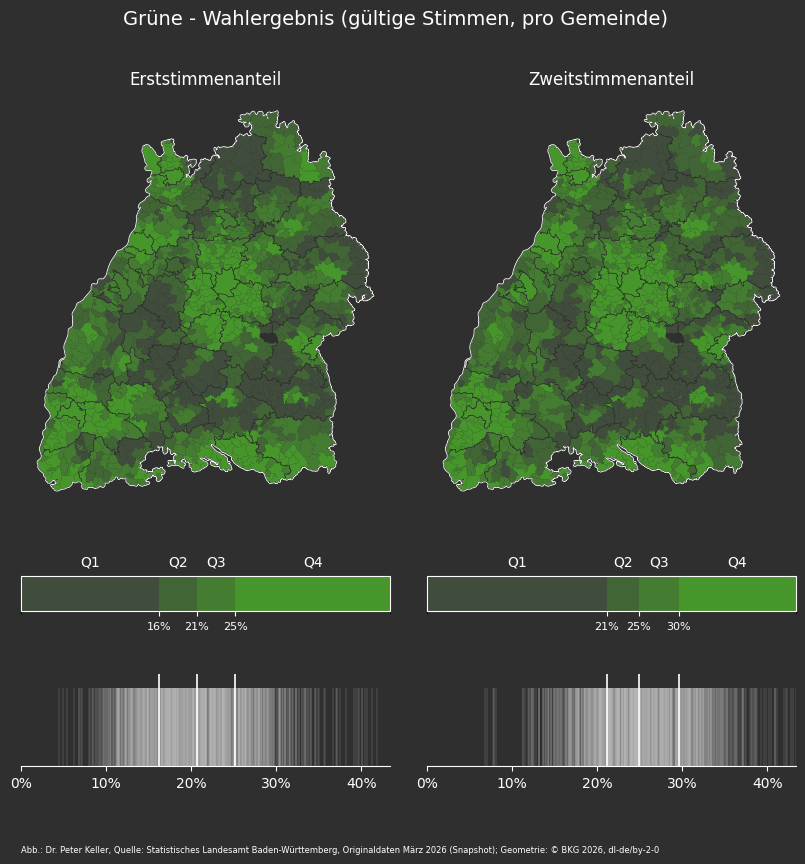

saved outputs/CDU_Wahlergebnis_LTW_BWB_2026.png


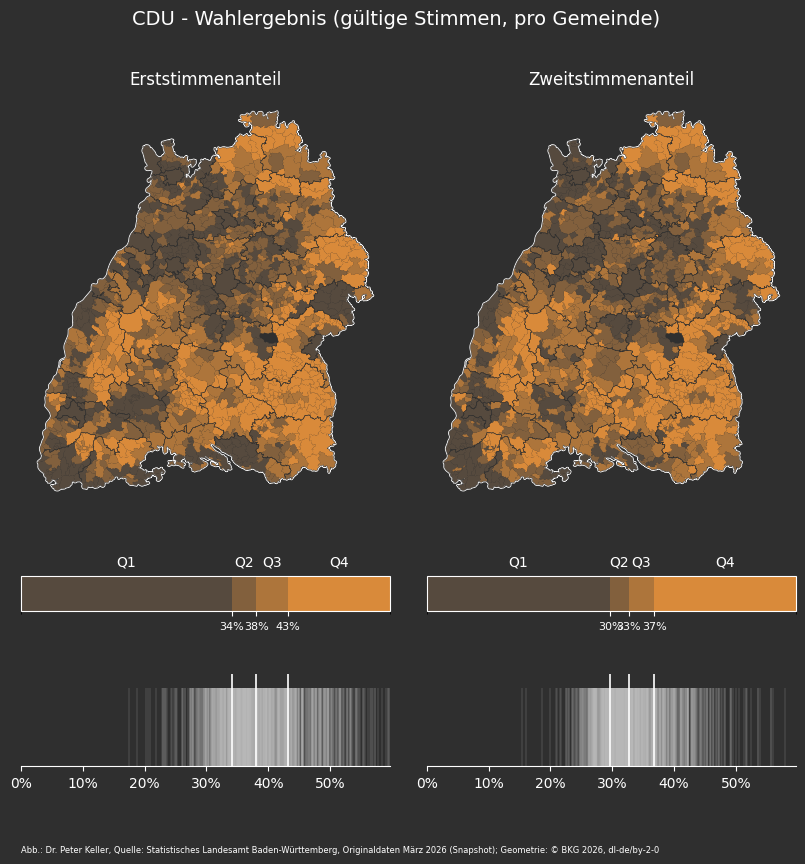

saved outputs/SPD_Wahlergebnis_LTW_BWB_2026.png


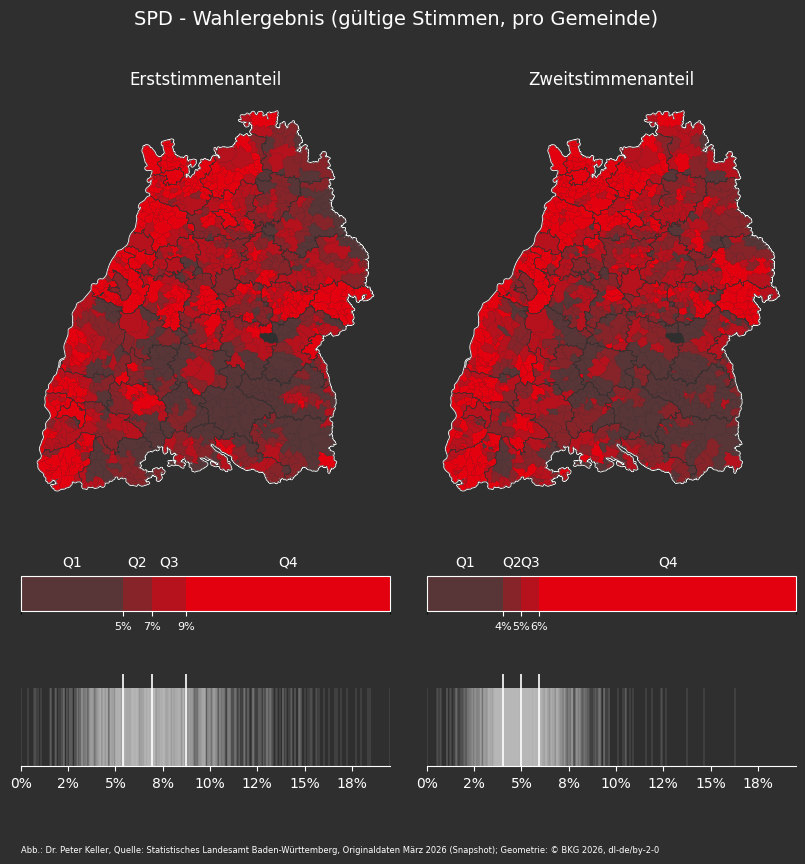

saved outputs/FDP_Wahlergebnis_LTW_BWB_2026.png


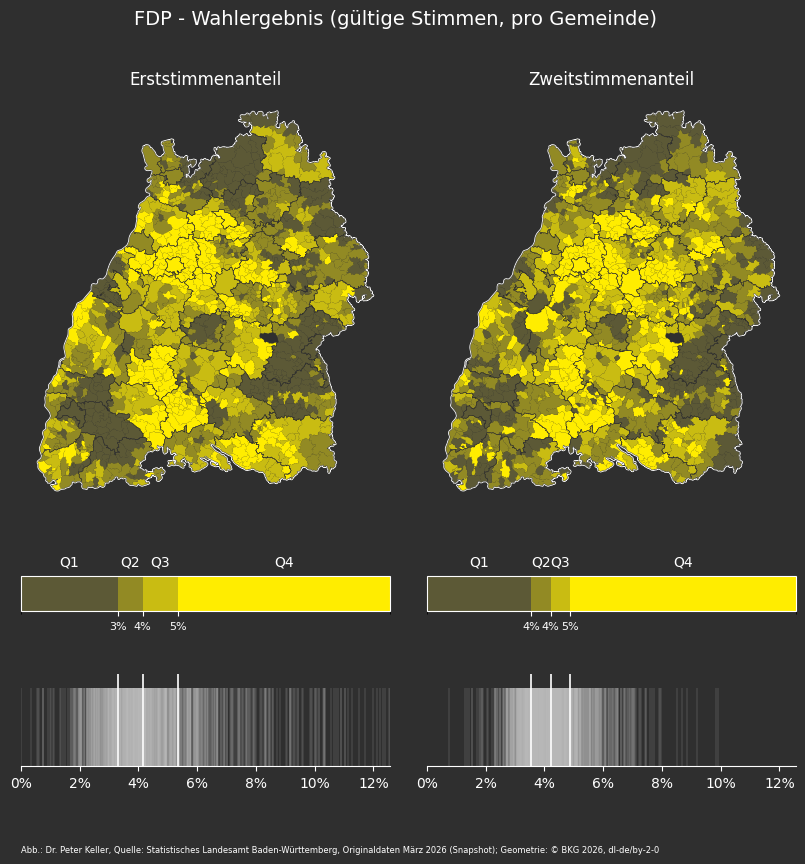

saved outputs/AfD_Wahlergebnis_LTW_BWB_2026.png


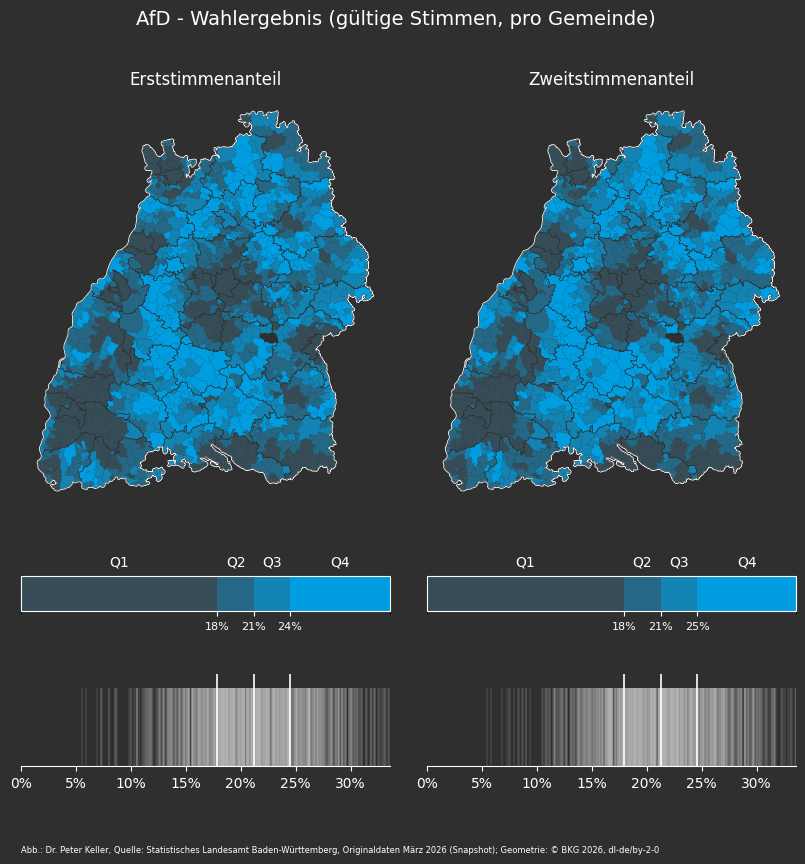

saved outputs/Die_Linke_Wahlergebnis_LTW_BWB_2026.png


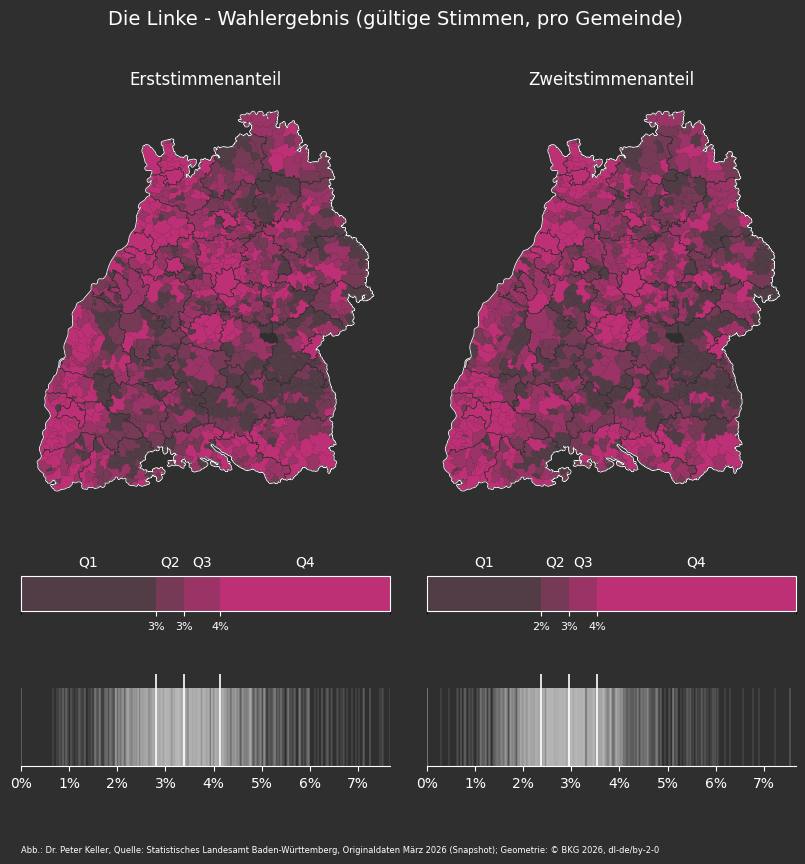

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm, to_rgb
from matplotlib.ticker import PercentFormatter
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

parties = [
    "GRUENE",
    "CDU",
    "SPD",
    "FDP",
    "AfD",
    "Die_Linke",
]

party_colors = {
    "GRUENE"   : "#46962b",
    "CDU"      : '#d98a3a', #"#000000",
    "SPD"      : "#e3000f",
    "FDP"      : "#ffed00",
    "AfD"      : "#009ee0",
    "Die_Linke": "#be3075",
}

party_labels = {
    "GRUENE": "Grüne",
    "CDU": "CDU",
    "SPD": "SPD",
    "FDP": "FDP",
    "AfD": "AfD",
    "Die_Linke": "Die Linke",
}

bg = np.array(to_rgb("#3f3f3f"))
white = np.array([1, 1, 1])

for party in parties:

    base = np.array(to_rgb(party_colors[party]))

    # =========================
    # Gemeinsame Skala pro Partei
    # =========================
    x_est = gdf[f"{party}_EST_p"].dropna()
    x_zst = gdf[f"{party}_ZST_p"].dropna()

    vmax_est = x_est.quantile(0.99)
    vmax_zst = x_zst.quantile(0.99)
    vmax = max(vmax_est, vmax_zst)
    vmin = 0

    # Quartilgrenzen getrennt für EST und ZST
    bins_est = np.r_[0, x_est.quantile([0.25, 0.50, 0.75]).to_numpy(), vmax]
    bins_zst = np.r_[0, x_zst.quantile([0.25, 0.50, 0.75]).to_numpy(), vmax]

    # defensive: streng monoton machen
    bins_est = np.maximum.accumulate(bins_est)
    bins_zst = np.maximum.accumulate(bins_zst)

    # =========================
    # Diskrete Quartil-Cmap aus Parteifarbe
    # =========================
    quartile_colors = []
    for w in np.linspace(0.15, 1.0, 4):
        col = (1 - w) * bg + w * base
        quartile_colors.append(tuple(np.clip(col, 0, 1)))

    cmap_party = ListedColormap(quartile_colors)

    norm_est = BoundaryNorm(bins_est, cmap_party.N)
    norm_zst = BoundaryNorm(bins_zst, cmap_party.N)

    sm_est = ScalarMappable(norm=norm_est, cmap=cmap_party)
    sm_est.set_array([])

    sm_zst = ScalarMappable(norm=norm_zst, cmap=cmap_party)
    sm_zst.set_array([])

    # =========================
    # Layout
    # =========================
    fig = plt.figure(figsize=(10, 8.8))
    fig.patch.set_facecolor("#2f2f2f")

    outer = fig.add_gridspec(
        3, 2,
        height_ratios=[12, 1.0, 2.6],
        width_ratios=[1, 1],
        hspace=0.34,
        wspace=0.10
    )

    ax0 = fig.add_subplot(outer[0, 0])   # EST Karte
    ax1 = fig.add_subplot(outer[0, 1])   # ZST Karte
    cax0 = fig.add_subplot(outer[1, 0])  # EST Legende
    cax1 = fig.add_subplot(outer[1, 1])  # ZST Legende
    ax2 = fig.add_subplot(outer[2, 0])   # EST Barcode
    ax3 = fig.add_subplot(outer[2, 1])   # ZST Barcode

    for ax in [ax0, ax1, cax0, cax1, ax2, ax3]:
        ax.set_facecolor("#2f2f2f")

    # =========================
    # Karten
    # =========================
    gdf.plot(
        ax=ax0,
        column=f"{party}_EST_p",
        cmap=cmap_party,
        norm=norm_est,
        zorder=5
    )

    gdf.plot(
        ax=ax1,
        column=f"{party}_ZST_p",
        cmap=cmap_party,
        norm=norm_zst,
        zorder=5
    )

    ax0.set_title("Erststimmenanteil", color="white")
    ax1.set_title("Zweitstimmenanteil", color="white")

    for ax in [ax0, ax1]:
        p2 = BWB.boundary.plot(ax=ax, facecolor="none", edgecolor="white", zorder=0)
        p2.set_path_effects([
            pe.Stroke(linewidth=1, foreground="white"),
            pe.Normal()
        ])
        # BWB_regbez.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=0.8, zorder=9)
        BWB_kreise.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=0.3, zorder=5)
        ax.set_axis_off()

    # =========================
    # Diskrete Farbleisten
    # =========================
    cb0 = fig.colorbar(
        sm_est,
        cax=cax0,
        orientation="horizontal",
        boundaries=bins_est,
        spacing="proportional"
    )

    cb1 = fig.colorbar(
        sm_zst,
        cax=cax1,
        orientation="horizontal",
        boundaries=bins_zst,
        spacing="proportional"
    )

    for cb in [cb0, cb1]:
        cb.ax.tick_params(colors="white", labelsize=8)
        cb.outline.set_edgecolor("white")

    cb0.set_ticks(bins_est[1:-1])
    cb0.ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

    cb1.set_ticks(bins_zst[1:-1])
    cb1.ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

    q1_est  = x_est.quantile(0.25)
    med_est = x_est.median()
    q3_est  = x_est.quantile(0.75)
    
    centers1 = 0.5 * (bins_est[:-1] + bins_est[1:])

    for i in range(4):
        cb0.ax.text(centers1[i], 1.21, f'Q{i+1}', color='white', ha='center', va='bottom')
    q1_zst  = x_zst.quantile(0.25)
    med_zst = x_zst.median()
    q3_zst  = x_zst.quantile(0.75)
    
    centers2 = 0.5 * (bins_zst[:-1] + bins_zst[1:])
    
    for i in range(4):
        cb1.ax.text(centers2[i], 1.21, f'Q{i+1}', color='white', ha='center', va='bottom')
        
    # =========================
    # Barcode-Plots
    # =========================

    ax2.vlines(x_est, ymin=0, ymax=1, alpha=0.12, color="#bfbfbf")
    ax2.axvline(med_est, color="white", linewidth=1.2)
    ax2.axvline(q1_est, color="white", linewidth=1.2)
    ax2.axvline(q3_est, color="white", linewidth=1.2)
    ax2.set_xlim(vmin, vmax)
    ax2.set_ylim(0, 1.18)
    ax2.set_yticks([])
    ax2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax2.tick_params(axis="x", colors="white")
    for side in ["top", "right", "left"]:
        ax2.spines[side].set_visible(False)
    ax2.spines["bottom"].set_color("white")

    med_zst = x_zst.median()
    q1_zst = x_zst.quantile(0.25)
    q3_zst = x_zst.quantile(0.75)

    ax3.vlines(x_zst, ymin=0, ymax=1, alpha=0.12, color="#bfbfbf")
    ax3.axvline(med_zst, color="white", linewidth=1.2)
    ax3.axvline(q1_zst, color="white", linewidth=1.2)
    ax3.axvline(q3_zst, color="white", linewidth=1.2)
    ax3.set_xlim(vmin, vmax)
    ax3.set_ylim(0, 1.18)
    ax3.set_yticks([])
    ax3.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax3.tick_params(axis="x", colors="white")
    for side in ["top", "right", "left"]:
        ax3.spines[side].set_visible(False)
    ax3.spines["bottom"].set_color("white")

    # =========================
    # Titel / Footer
    # =========================
    fig.suptitle(
        f"{party_labels[party]} - Wahlergebnis (gültige Stimmen, pro Gemeinde)",
        color="white",
        fontsize=14,
        y=0.97
    )

    fig.text(
        0.125, 0.01,
        "Abb.: Dr. Peter Keller, Quelle: Statistisches Landesamt Baden-Württemberg, Originaldaten März 2026 (Snapshot); Geometrie: © BKG 2026, dl-de/by-2-0",
        fontsize=6,
        ha="left",
        va="bottom",
        color="white"
    )

    filename = f"outputs/{party}_Wahlergebnis_LTW_BWB_2026.png"
    dpi = 120

    fig.savefig(
        filename,
        dpi=dpi,
        bbox_inches="tight",
        transparent=False,
    )
    print(f"saved {filename}")

    plt.show()

## 4. Zwei Anteile gleichzeitig: bivariate Quartilkarten

Die bivariate Karte zeigt, ob CDU und Grüne jeweils relativ hohe oder niedrige Anteile erreichen. Die beiden Einzelkarten und Barcodes darunter bleiben als Lesehilfe erhalten. Ein hohes Quartil bei beiden Parteien sagt nichts darüber aus, welche von beiden vorne liegt.

Erst- und Zweitstimmen werden ausdrücklich getrennt erzeugt. Die Quartile werden je Stimmenart berechnet; die beiden Karten sind daher relativ, nicht auf einer gemeinsamen absoluten Skala vergleichbar.


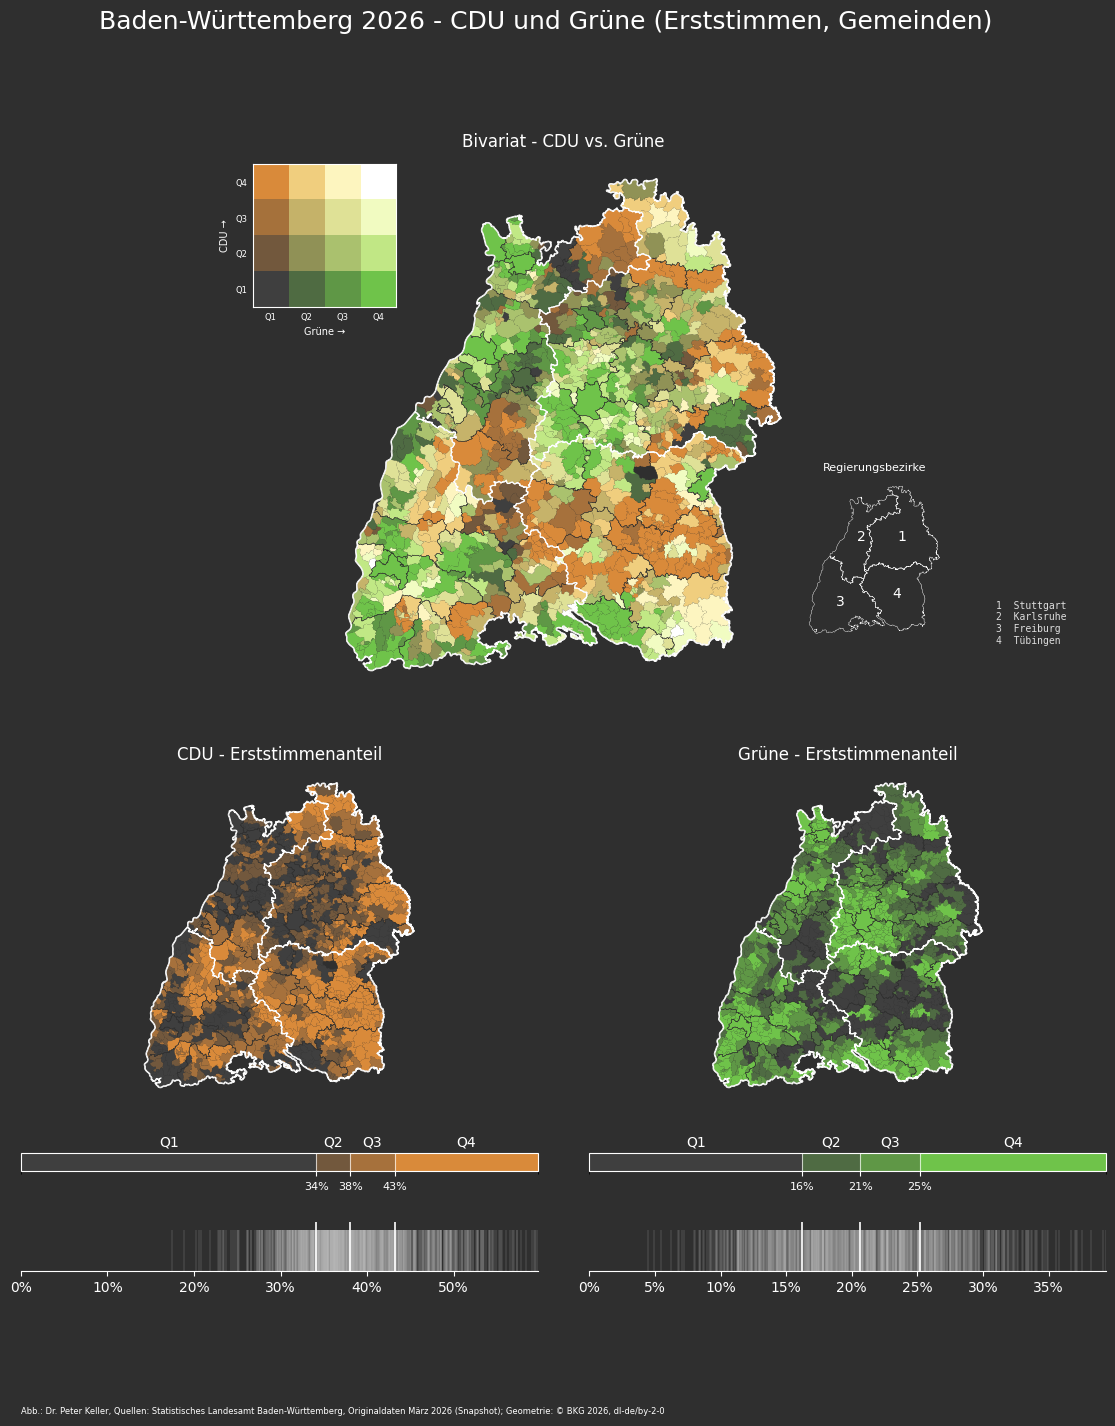

saved outputs/EST_Wahlergebnis_LTW_BW_2026.png


In [8]:
from matplotlib.colors import ListedColormap, BoundaryNorm, to_rgb
from matplotlib.ticker import PercentFormatter
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# =========================
# EINSTELLUNGEN
# =========================
vote_type = "EST"   # "EST" oder "ZST"

var1 = f"CDU_{vote_type}_p"
var2 = f"GRUENE_{vote_type}_p"

label1 = "CDU"
label2 = "Grüne"

# 4 Quantilklassen
gdf[f"{label1}_q"] = quartiles(gdf[var1])
gdf[f"{label2}_q"] = quartiles(gdf[var2])

# Index 0..15
gdf["bivar_idx"] = gdf[f"{label1}_q"] * 4 + gdf[f"{label2}_q"]

bg = np.array(to_rgb("#3f3f3f"))
cdu = np.array(to_rgb("#d98a3a"))
gru = np.array(to_rgb("#6fc34a"))
white = np.array([1, 1, 1])

colors_biv = []
for i in range(4):
    for j in range(4):
        w_cdu = i / 3
        w_gru = j / 3
        base = (1 - w_cdu - w_gru) * bg + w_cdu * cdu + w_gru * gru
        mix = (w_cdu * w_gru) * white + (1 - w_cdu * w_gru) * base
        colors_biv.append(mix)

colors_biv = np.clip(colors_biv, 0, 1)
colors_biv = [tuple(c) for c in colors_biv]

bivar_cmap = ListedColormap(colors_biv)
gdf["bivar_color"] = gdf["bivar_idx"].map(dict(enumerate(colors_biv)))

# eindimensionale Colormaps aus bivariater Matrix
biv_mat = np.array(colors_biv, dtype=float).reshape(4, 4, 3)
cdu_colors = biv_mat[:, 0, :]
gruene_colors = biv_mat[0, :, :]

cmap1 = ListedColormap(cdu_colors)
cmap2 = ListedColormap(gruene_colors)

# 99%-Grenzen für Barcode-Achsen
vmax1 = gdf[var1].quantile(0.99)
vmax2 = gdf[var2].quantile(0.99)

# Quartilgrenzen als Klassengrenzen
bins1 = np.r_[0, gdf[var1].quantile([0.25, 0.50, 0.75]).to_numpy(), vmax1]
bins2 = np.r_[0, gdf[var2].quantile([0.25, 0.50, 0.75]).to_numpy(), vmax2]

norm1 = BoundaryNorm(bins1, cmap1.N)
norm2 = BoundaryNorm(bins2, cmap2.N)

sm1 = ScalarMappable(norm=norm1, cmap=cmap1)
sm1.set_array([])

sm2 = ScalarMappable(norm=norm2, cmap=cmap2)
sm2.set_array([])

# =========================
# LAYOUT
# =========================
fig = plt.figure(figsize=(14, 14.5))
fig.patch.set_facecolor("#2f2f2f")

outer = fig.add_gridspec(
    2, 2,
    height_ratios=[1.45, 1.35],
    width_ratios=[1, 1],
    hspace=0.14,
    wspace=0.10
)

# oben groß: bivariate Karte über beide Spalten
ax2 = fig.add_subplot(outer[0, :])

# unten links: CDU = Karte, Legende, Barcode
left = outer[1, 0].subgridspec(
    3, 1,
    height_ratios=[16.5, 0.9, 2.4],
    hspace=0.38
)
ax0 = fig.add_subplot(left[0, 0])
cax0 = fig.add_subplot(left[1, 0])
ax3 = fig.add_subplot(left[2, 0])

# unten rechts: Grüne = Karte, Legende, Barcode
right = outer[1, 1].subgridspec(
    3, 1,
    height_ratios=[16.5, 0.9, 2.4],
    hspace=0.38
)
ax1 = fig.add_subplot(right[0, 0])
cax1 = fig.add_subplot(right[1, 0])
ax4 = fig.add_subplot(right[2, 0])

for ax in [ax0, ax1, ax2, ax3, ax4, cax0, cax1]:
    ax.set_facecolor("#2f2f2f")

# =========================
# KARTEN
# =========================
gdf.plot(
    column=var1,
    legend=False,
    ax=ax0,
    cmap=cmap1,
    norm=norm1,
    zorder=5,
)

gdf.plot(
    column=var2,
    legend=False,
    ax=ax1,
    cmap=cmap2,
    norm=norm2,
    zorder=5,
)

gdf.plot(
    color=gdf["bivar_color"],
    legend=False,
    ax=ax2,
    zorder=5,
)

ax0.set_title(f"{label1} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax1.set_title(f"{label2} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax2.set_title(f"Bivariat - {label1} vs. {label2}", color="white")

for ax in [ax0, ax1, ax2]:
    p2 = BWB.boundary.plot(ax=ax, facecolor="#2f2f2f", edgecolor="white", zorder=0)
    p2.set_path_effects([
        pe.Stroke(linewidth=1.5, foreground="white"),
        pe.Normal()
    ])
    BWB_kreise.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=0.3, zorder=10)
    BWB_regbez.boundary.plot(ax=ax, edgecolor="#ffffff", linewidth=0.8, zorder=11)
    ax.set_axis_off()

# =========================
# FARBLEISTEN
# =========================
cb0 = fig.colorbar(
    sm1,
    cax=cax0,
    orientation="horizontal",
    boundaries=bins1,
    spacing="proportional"
)

cb1 = fig.colorbar(
    sm2,
    cax=cax1,
    orientation="horizontal",
    boundaries=bins2,
    spacing="proportional"
)

for cb in [cb0, cb1]:
    cb.ax.tick_params(colors="white", labelsize=8)
    cb.outline.set_edgecolor("white")

cb0.set_ticks(bins1[1:-1])
cb0.ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

cb1.set_ticks(bins2[1:-1])
cb1.ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

x1 = gdf[var1].dropna()

q11 = x1.quantile(0.25)
med1 = x1.median()
q13 = x1.quantile(0.75)

centers1 = 0.5 * (bins1[:-1] + bins1[1:])

for i in range(4):
    cb0.ax.text(centers1[i], 1.21, f'Q{i+1}', color='white', ha='center', va='bottom')

cb0.ax.axvline(med1, color="white", linewidth=0.8, alpha=0.7)
cb0.ax.axvline( q11, color="white", linewidth=0.8, alpha=0.7)
cb0.ax.axvline( q13, color="white", linewidth=0.8, alpha=0.7)


x2 = gdf[var2].dropna()

q21 = x2.quantile(0.25)
med2 = x2.median()
q23 = x2.quantile(0.75)

centers2 = 0.5 * (bins2[:-1] + bins2[1:])

for i in range(4):
    cb1.ax.text(centers2[i], 1.21, f'Q{i+1}', color='white', ha='center', va='bottom')

cb1.ax.axvline(med2, color="white", linewidth=0.8, alpha=0.7)
cb1.ax.axvline( q21, color="white", linewidth=0.8, alpha=0.7)
cb1.ax.axvline( q23, color="white", linewidth=0.8, alpha=0.7)

# =========================
# FARBLEGENDE 4x4 im bivariaten Plot
# =========================
legend_matrix = np.arange(16).reshape(4, 4)

cax = ax2.inset_axes([-0.15, 0.70, 0.3, 0.3])
cax.imshow(legend_matrix[::-1], cmap=bivar_cmap)

cax.set_xticks(range(4))
cax.set_yticks(range(4))
cax.set_xticklabels([f"Q{i}" for i in range(1, 5)], color="white", fontsize=6)
cax.set_yticklabels([f"Q{i}" for i in range(4, 0, -1)], color="white", fontsize=6)

cax.set_xlabel(f"{label2} →", color="white", fontsize=7)
cax.set_ylabel(f"{label1} →", color="white", fontsize=7)
cax.tick_params(length=0)

for spine in cax.spines.values():
    spine.set_edgecolor("white")
cax.set_facecolor("#122635")

# =========================
# Inset Regierungsbezirke
# =========================

regbez_map = ax2.inset_axes([1, 0.1, 0.3, 0.3])

BWB_regbez.boundary.plot(ax=regbez_map, edgecolor="white", facecolor="none", linewidth=0.3)

regbez_map.set_xticks([])
regbez_map.set_yticks([])
regbez_map.set_title("Regierungsbezirke", fontsize=8, color = '#ffffff')

for spine in regbez_map.spines.values():
    spine.set_edgecolor('white')

regbez_map.set_facecolor('none')
regbez_map.set_frame_on(False)

xs = BWB_regbez.centers.geometry.x
ys = BWB_regbez.centers.geometry.y
nrs = BWB_regbez.RegBez_Nr

for x, y, nr in zip(xs, ys, nrs):
    regbez_map.text(x, y, nr, ha = 'center', va = 'center', color = '#ffffff')

liste = "\n".join(
    f"{row['RegBez_Nr']}  {row['RegBez_Name']}"
    for _, row in BWB_regbez[['RegBez_Nr', 'RegBez_Name']].iterrows()
)

regbez_map.text(
    1.35, 0.25,
    liste,
    transform=regbez_map.transAxes,
    fontsize=7,
    color="#dddddd",
    va="top",
    family="monospace"
)


# =========================
# BARCODE-PLOTS
# =========================

ax3.vlines(x1, ymin=0, ymax=1, alpha=0.12, color= '#bfbfbf')  # war color = tuple(cdu)
ax3.axvline(med1, color="white", linewidth=1.2)
ax3.axvline(q11, color="white", linewidth=1.2)
ax3.axvline(q13, color="white", linewidth=1.2)
# ax3.text(
#     med1, 1.12, f"Median: {med1:.1%}",
#     color="white", fontsize=8, ha="center", va="bottom"
# )
ax3.set_xlim(0, vmax1)
ax3.set_ylim(0, 1.18)
ax3.set_yticks([])
# ax3.set_xlabel(f"{label1} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax3.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax3.tick_params(axis="x", colors="white")
for side in ["top", "right", "left"]:
    ax3.spines[side].set_visible(False)
ax3.spines["bottom"].set_color("white")




ax4.vlines(x2, ymin=0, ymax=1, alpha=0.12, color= '#bfbfbf') # war color = tuple(gru)
ax4.axvline(med2, color="white", linewidth=1.2)
ax4.axvline(q21, color="white", linewidth=1.2)
ax4.axvline(q23, color="white", linewidth=1.2)

# ax4.text(
#     med2, 1.12, f"Median: {med2:.1%}",
#     color="white", fontsize=8, ha="center", va="bottom"
# )
ax4.set_xlim(0, vmax2)
ax4.set_ylim(0, 1.18)
ax4.set_yticks([])
# ax4.set_xlabel(f"{label2} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax4.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax4.tick_params(axis="x", colors="white")
for side in ["top", "right", "left"]:
    ax4.spines[side].set_visible(False)
ax4.spines["bottom"].set_color("white")

# =========================
# TITEL / FOOTER
# =========================
fig.suptitle(
    f"Baden-Württemberg 2026 - {label1} und {label2} ({'Erststimmen' if vote_type=='EST' else 'Zweitstimmen'}, Gemeinden)",
    color="white",
    fontsize=18,
    y=0.98
)

fig.text(
    0.125, 0.01,
    "Abb.: Dr. Peter Keller, Quellen: Statistisches Landesamt Baden-Württemberg, Originaldaten März 2026 (Snapshot); Geometrie: © BKG 2026, dl-de/by-2-0",
    fontsize=6,
    ha="left",
    va="bottom",
    color="white"
)

plt.show()
filename = f'outputs/{vote_type}_Wahlergebnis_LTW_BW_2026.png'
dpi = 120

fig.savefig(
    filename, 
    dpi=dpi,
    bbox_inches="tight",
    transparent = False,
)
print(f'saved {filename}')
plt.close(fig)

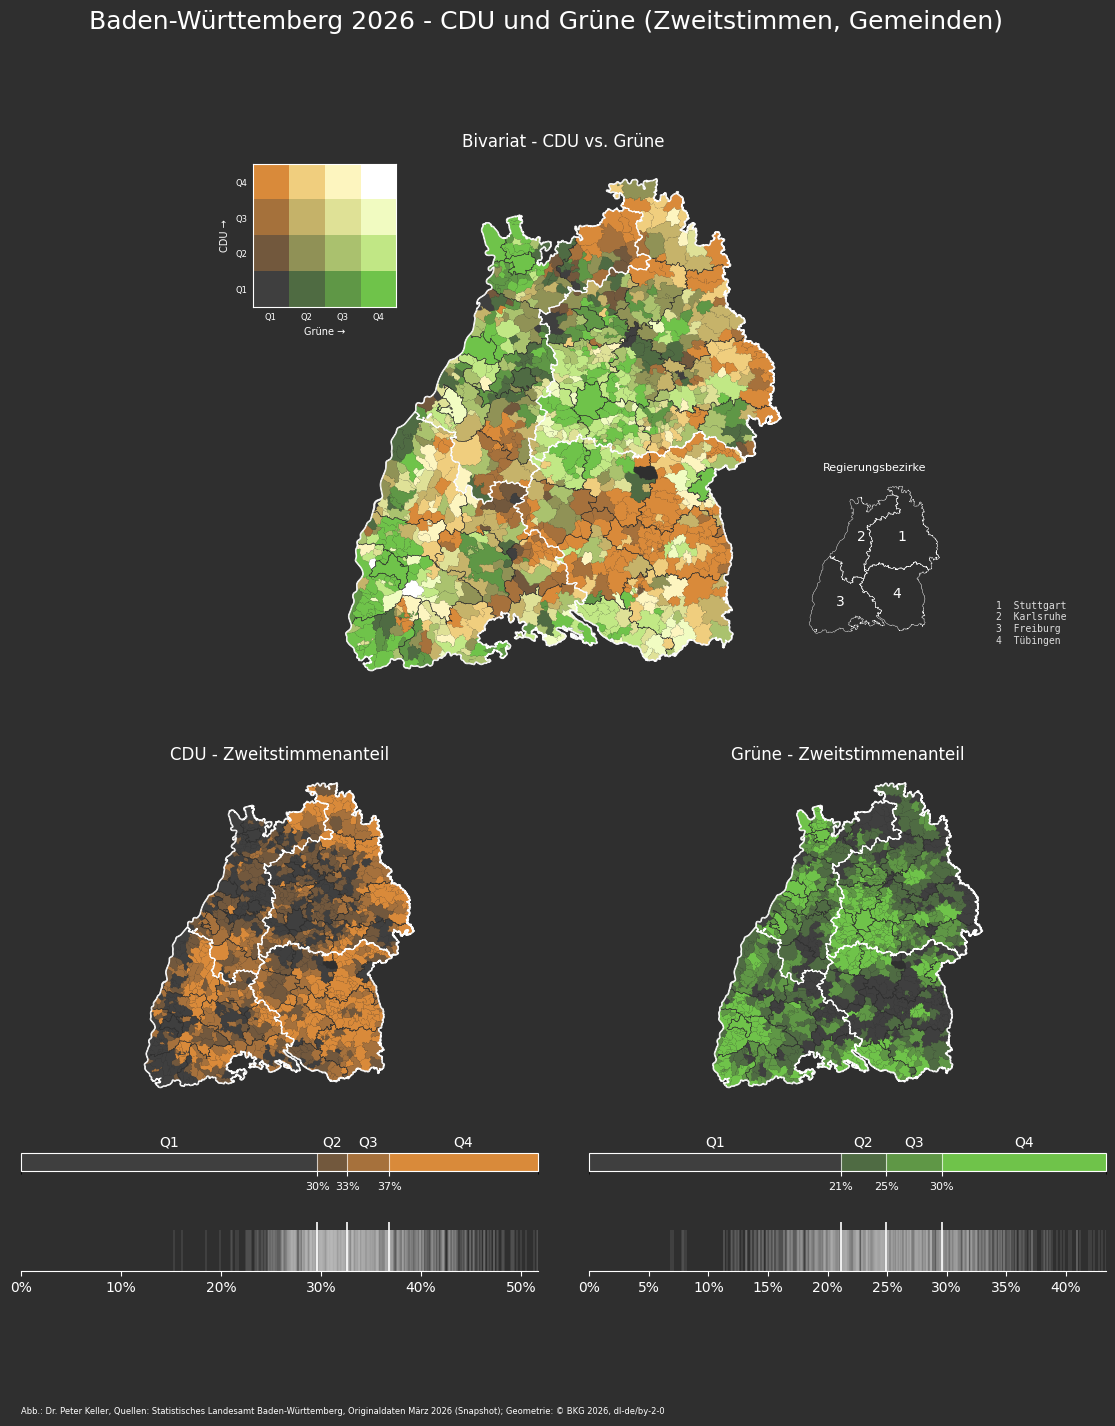

saved outputs/ZST_Wahlergebnis_LTW_BW_2026.png


In [9]:
from matplotlib.colors import ListedColormap, BoundaryNorm, to_rgb
from matplotlib.ticker import PercentFormatter
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# =========================
# EINSTELLUNGEN
# =========================
vote_type = "ZST"   # "EST" oder "ZST"

var1 = f"CDU_{vote_type}_p"
var2 = f"GRUENE_{vote_type}_p"

label1 = "CDU"
label2 = "Grüne"

# 4 Quantilklassen
gdf[f"{label1}_q"] = quartiles(gdf[var1])
gdf[f"{label2}_q"] = quartiles(gdf[var2])

# Index 0..15
gdf["bivar_idx"] = gdf[f"{label1}_q"] * 4 + gdf[f"{label2}_q"]

bg = np.array(to_rgb("#3f3f3f"))
cdu = np.array(to_rgb("#d98a3a"))
gru = np.array(to_rgb("#6fc34a"))
white = np.array([1, 1, 1])

colors_biv = []
for i in range(4):
    for j in range(4):
        w_cdu = i / 3
        w_gru = j / 3
        base = (1 - w_cdu - w_gru) * bg + w_cdu * cdu + w_gru * gru
        mix = (w_cdu * w_gru) * white + (1 - w_cdu * w_gru) * base
        colors_biv.append(mix)

colors_biv = np.clip(colors_biv, 0, 1)
colors_biv = [tuple(c) for c in colors_biv]

bivar_cmap = ListedColormap(colors_biv)
gdf["bivar_color"] = gdf["bivar_idx"].map(dict(enumerate(colors_biv)))

# eindimensionale Colormaps aus bivariater Matrix
biv_mat = np.array(colors_biv, dtype=float).reshape(4, 4, 3)
cdu_colors = biv_mat[:, 0, :]
gruene_colors = biv_mat[0, :, :]

cmap1 = ListedColormap(cdu_colors)
cmap2 = ListedColormap(gruene_colors)

# 99%-Grenzen für Barcode-Achsen
vmax1 = gdf[var1].quantile(0.99)
vmax2 = gdf[var2].quantile(0.99)

# Quartilgrenzen als Klassengrenzen
bins1 = np.r_[0, gdf[var1].quantile([0.25, 0.50, 0.75]).to_numpy(), vmax1]
bins2 = np.r_[0, gdf[var2].quantile([0.25, 0.50, 0.75]).to_numpy(), vmax2]

norm1 = BoundaryNorm(bins1, cmap1.N)
norm2 = BoundaryNorm(bins2, cmap2.N)

sm1 = ScalarMappable(norm=norm1, cmap=cmap1)
sm1.set_array([])

sm2 = ScalarMappable(norm=norm2, cmap=cmap2)
sm2.set_array([])

# =========================
# LAYOUT
# =========================
fig = plt.figure(figsize=(14, 14.5))
fig.patch.set_facecolor("#2f2f2f")

outer = fig.add_gridspec(
    2, 2,
    height_ratios=[1.45, 1.35],
    width_ratios=[1, 1],
    hspace=0.14,
    wspace=0.10
)

# oben groß: bivariate Karte über beide Spalten
ax2 = fig.add_subplot(outer[0, :])

# unten links: CDU = Karte, Legende, Barcode
left = outer[1, 0].subgridspec(
    3, 1,
    height_ratios=[16.5, 0.9, 2.4],
    hspace=0.38
)
ax0 = fig.add_subplot(left[0, 0])
cax0 = fig.add_subplot(left[1, 0])
ax3 = fig.add_subplot(left[2, 0])

# unten rechts: Grüne = Karte, Legende, Barcode
right = outer[1, 1].subgridspec(
    3, 1,
    height_ratios=[16.5, 0.9, 2.4],
    hspace=0.38
)
ax1 = fig.add_subplot(right[0, 0])
cax1 = fig.add_subplot(right[1, 0])
ax4 = fig.add_subplot(right[2, 0])

for ax in [ax0, ax1, ax2, ax3, ax4, cax0, cax1]:
    ax.set_facecolor("#2f2f2f")

# =========================
# KARTEN
# =========================
gdf.plot(
    column=var1,
    legend=False,
    ax=ax0,
    cmap=cmap1,
    norm=norm1,
    zorder=5,
)

gdf.plot(
    column=var2,
    legend=False,
    ax=ax1,
    cmap=cmap2,
    norm=norm2,
    zorder=5,
)

gdf.plot(
    color=gdf["bivar_color"],
    legend=False,
    ax=ax2,
    zorder=5,
)

ax0.set_title(f"{label1} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax1.set_title(f"{label2} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax2.set_title(f"Bivariat - {label1} vs. {label2}", color="white")

for ax in [ax0, ax1, ax2]:
    p2 = BWB.boundary.plot(ax=ax, facecolor="#2f2f2f", edgecolor="white", zorder=0)
    p2.set_path_effects([
        pe.Stroke(linewidth=1.5, foreground="white"),
        pe.Normal()
    ])
    BWB_kreise.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=0.3, zorder=10)
    BWB_regbez.boundary.plot(ax=ax, edgecolor="#ffffff", linewidth=0.8, zorder=11)
    ax.set_axis_off()

# =========================
# FARBLEISTEN
# =========================
cb0 = fig.colorbar(
    sm1,
    cax=cax0,
    orientation="horizontal",
    boundaries=bins1,
    spacing="proportional"
)

cb1 = fig.colorbar(
    sm2,
    cax=cax1,
    orientation="horizontal",
    boundaries=bins2,
    spacing="proportional"
)

for cb in [cb0, cb1]:
    cb.ax.tick_params(colors="white", labelsize=8)
    cb.outline.set_edgecolor("white")

cb0.set_ticks(bins1[1:-1])
cb0.ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

cb1.set_ticks(bins2[1:-1])
cb1.ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

x1 = gdf[var1].dropna()

q11 = x1.quantile(0.25)
med1 = x1.median()
q13 = x1.quantile(0.75)

centers1 = 0.5 * (bins1[:-1] + bins1[1:])

for i in range(4):
    cb0.ax.text(centers1[i], 1.21, f'Q{i+1}', color='white', ha='center', va='bottom')

cb0.ax.axvline(med1, color="white", linewidth=0.8, alpha=0.7)
cb0.ax.axvline( q11, color="white", linewidth=0.8, alpha=0.7)
cb0.ax.axvline( q13, color="white", linewidth=0.8, alpha=0.7)


x2 = gdf[var2].dropna()

q21 = x2.quantile(0.25)
med2 = x2.median()
q23 = x2.quantile(0.75)

centers2 = 0.5 * (bins2[:-1] + bins2[1:])

for i in range(4):
    cb1.ax.text(centers2[i], 1.21, f'Q{i+1}', color='white', ha='center', va='bottom')

cb1.ax.axvline(med2, color="white", linewidth=0.8, alpha=0.7)
cb1.ax.axvline( q21, color="white", linewidth=0.8, alpha=0.7)
cb1.ax.axvline( q23, color="white", linewidth=0.8, alpha=0.7)

# =========================
# FARBLEGENDE 4x4 im bivariaten Plot
# =========================
legend_matrix = np.arange(16).reshape(4, 4)

cax = ax2.inset_axes([-0.15, 0.70, 0.3, 0.3])
cax.imshow(legend_matrix[::-1], cmap=bivar_cmap)

cax.set_xticks(range(4))
cax.set_yticks(range(4))
cax.set_xticklabels([f"Q{i}" for i in range(1, 5)], color="white", fontsize=6)
cax.set_yticklabels([f"Q{i}" for i in range(4, 0, -1)], color="white", fontsize=6)

cax.set_xlabel(f"{label2} →", color="white", fontsize=7)
cax.set_ylabel(f"{label1} →", color="white", fontsize=7)
cax.tick_params(length=0)

for spine in cax.spines.values():
    spine.set_edgecolor("white")
cax.set_facecolor("#122635")

# =========================
# Inset Regierungsbezirke
# =========================

regbez_map = ax2.inset_axes([1, 0.1, 0.3, 0.3])

BWB_regbez.boundary.plot(ax=regbez_map, edgecolor="white", facecolor="none", linewidth=0.3)

regbez_map.set_xticks([])
regbez_map.set_yticks([])
regbez_map.set_title("Regierungsbezirke", fontsize=8, color = '#ffffff')

for spine in regbez_map.spines.values():
    spine.set_edgecolor('white')

regbez_map.set_facecolor('none')
regbez_map.set_frame_on(False)

xs = BWB_regbez.centers.geometry.x
ys = BWB_regbez.centers.geometry.y
nrs = BWB_regbez.RegBez_Nr

for x, y, nr in zip(xs, ys, nrs):
    regbez_map.text(x, y, nr, ha = 'center', va = 'center', color = '#ffffff')

liste = "\n".join(
    f"{row['RegBez_Nr']}  {row['RegBez_Name']}"
    for _, row in BWB_regbez[['RegBez_Nr', 'RegBez_Name']].iterrows()
)

regbez_map.text(
    1.35, 0.25,
    liste,
    transform=regbez_map.transAxes,
    fontsize=7,
    color="#dddddd",
    va="top",
    family="monospace"
)


# =========================
# BARCODE-PLOTS
# =========================

ax3.vlines(x1, ymin=0, ymax=1, alpha=0.12, color= '#bfbfbf')  # war color = tuple(cdu)
ax3.axvline(med1, color="white", linewidth=1.2)
ax3.axvline(q11, color="white", linewidth=1.2)
ax3.axvline(q13, color="white", linewidth=1.2)
# ax3.text(
#     med1, 1.12, f"Median: {med1:.1%}",
#     color="white", fontsize=8, ha="center", va="bottom"
# )
ax3.set_xlim(0, vmax1)
ax3.set_ylim(0, 1.18)
ax3.set_yticks([])
# ax3.set_xlabel(f"{label1} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax3.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax3.tick_params(axis="x", colors="white")
for side in ["top", "right", "left"]:
    ax3.spines[side].set_visible(False)
ax3.spines["bottom"].set_color("white")




ax4.vlines(x2, ymin=0, ymax=1, alpha=0.12, color= '#bfbfbf') # war color = tuple(gru)
ax4.axvline(med2, color="white", linewidth=1.2)
ax4.axvline(q21, color="white", linewidth=1.2)
ax4.axvline(q23, color="white", linewidth=1.2)

# ax4.text(
#     med2, 1.12, f"Median: {med2:.1%}",
#     color="white", fontsize=8, ha="center", va="bottom"
# )
ax4.set_xlim(0, vmax2)
ax4.set_ylim(0, 1.18)
ax4.set_yticks([])
# ax4.set_xlabel(f"{label2} - {'Erst' if vote_type=='EST' else 'Zweit'}stimmenanteil", color="white")
ax4.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax4.tick_params(axis="x", colors="white")
for side in ["top", "right", "left"]:
    ax4.spines[side].set_visible(False)
ax4.spines["bottom"].set_color("white")

# =========================
# TITEL / FOOTER
# =========================
fig.suptitle(
    f"Baden-Württemberg 2026 - {label1} und {label2} ({'Erststimmen' if vote_type=='EST' else 'Zweitstimmen'}, Gemeinden)",
    color="white",
    fontsize=18,
    y=0.98
)

fig.text(
    0.125, 0.01,
    "Abb.: Dr. Peter Keller, Quellen: Statistisches Landesamt Baden-Württemberg, Originaldaten März 2026 (Snapshot); Geometrie: © BKG 2026, dl-de/by-2-0",
    fontsize=6,
    ha="left",
    va="bottom",
    color="white"
)

plt.show()
filename = f'outputs/{vote_type}_Wahlergebnis_LTW_BW_2026.png'
dpi = 120

fig.savefig(
    filename, 
    dpi=dpi,
    bbox_inches="tight",
    transparent = False,
)
print(f'saved {filename}')
plt.close(fig)

## 5. Wer liegt vorne? Kontinuierliches log(CDU/Grüne)

Das Verhältnis beantwortet eine andere Frage als die Quartilkarte: Bei 1 liegen beide gleichauf. Der natürliche Logarithmus macht die Richtungen symmetrisch: log(2) und log(1/2) liegen gleich weit von null entfernt. Die kontinuierliche Karte bewahrt feine Unterschiede; sie zeigt aber nicht, wie groß beide Parteien zusammen sind.

Die Farbspanne wird aus dem 1%- und 99%-Quantil symmetrisch um null gewählt. Außerhalb dieser Spanne sättigen die Farben. Nicht definierte Verhältnisse werden nicht durch willkürliche Pseudostimmen ersetzt.


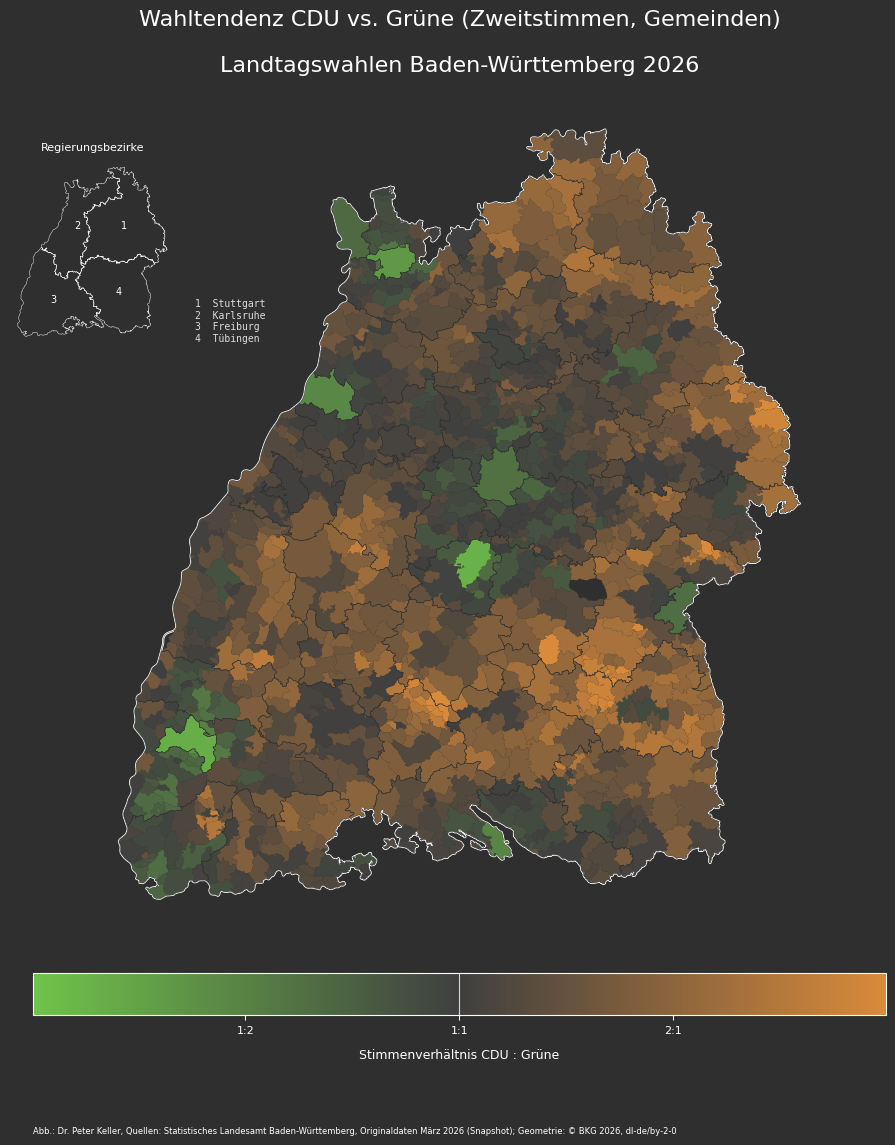

saved outputs/ZST_Wahlergebnis_LTW_BW_2026_logratio.png


In [10]:
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np

# =========================
# EINSTELLUNGEN
# =========================
vote_type = "ZST"   # "EST" oder "ZST"

label1 = "CDU"
label2 = "Grüne"

# =========================
# INDEX
# =========================
# R_log = natürlicher Logarithmus des CDU/Grüne-Verhältnisses
vmin = gdf["R_log"].quantile(0.01)
vmax = gdf["R_log"].quantile(0.99)

m = max(abs(vmin), abs(vmax))
norm = TwoSlopeNorm(vmin=-m, vcenter=0, vmax=m)

cmap = LinearSegmentedColormap.from_list(
    "gru_cdu",
    ["#6fc34a", "#3f3f3f", "#d98a3a"]
)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# =========================
# LAYOUT
# =========================
fig = plt.figure(figsize=(11, 12))
fig.patch.set_facecolor("#2f2f2f")

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[18, 0.9],
    hspace=0.08
)

ax = fig.add_subplot(gs[0, 0])
cax = fig.add_subplot(gs[1, 0])

ax.set_facecolor("#2f2f2f")
cax.set_facecolor("#2f2f2f")

# =========================
# KARTE
# =========================
gdf.plot(
    column="R_log",
    ax=ax,
    cmap=cmap,
    norm=norm,
    linewidth=0,
    zorder=5
)

p2 = BWB.boundary.plot(ax=ax, edgecolor="white", zorder=0)
p2.set_path_effects([
    pe.Stroke(linewidth=1.5, foreground="white"),
    pe.Normal()
])

BWB_kreise.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=0.3, zorder=10)
# BWB_regbez.boundary.plot(ax=ax, edgecolor="#ffffff", linewidth=0.8, zorder=11, alpha = 0.2)

ax.set_title(
    f"Wahltendenz {label1} vs. {label2} (Zweitstimmen, Gemeinden)\n\nLandtagswahlen Baden-Württemberg 2026",
    color="white",
    fontsize=16,
    pad=14
)
ax.set_axis_off()

# =========================
# FARBLEISTE
# =========================
cb = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cb.ax.tick_params(colors="white", labelsize=8)
cb.outline.set_edgecolor("white")

# gewünschte log-Ratio Referenzen
ticks_all = np.array([-np.log(4), -np.log(2), 0, np.log(2), np.log(4)])
labels_all = ["1:4", "1:2", "1:1", "2:1", "4:1"]

# nur Ticks anzeigen, die innerhalb der aktuellen Farbskala liegen
mask = (ticks_all >= -m) & (ticks_all <= m)
ticks = ticks_all[mask]
labels = [lab for lab, keep in zip(labels_all, mask) if keep]

cb.set_ticks(ticks)
cb.set_ticklabels(labels)

cb.set_label(
    'Stimmenverhältnis CDU : Grüne',
    color='white',
    fontsize = 9,
    labelpad = 10,
)

# Neutralpunkt markieren
cb.ax.axvline(0, color="white", linewidth=0.8, alpha=0.8)


# =========================
# INSET REGIERUNGSBEZIRKE
# =========================
regbez_map = ax.inset_axes([-0.1, 0.7, 0.22, 0.22])

BWB_regbez.boundary.plot(
    ax=regbez_map,
    edgecolor="white",
    facecolor="none",
    linewidth=0.4,
    alpha = 0.8,
)

regbez_map.set_xticks([])
regbez_map.set_yticks([])
regbez_map.set_title("Regierungsbezirke", fontsize=8, color="white")
regbez_map.set_facecolor("none")
regbez_map.set_frame_on(False)

xs = BWB_regbez.centers.geometry.x
ys = BWB_regbez.centers.geometry.y
nrs = BWB_regbez.RegBez_Nr

for x, y, nr in zip(xs, ys, nrs):
    regbez_map.text(
        x, y, nr,
        ha="center", va="center",
        color="white", fontsize=7
    )

liste = "\n".join(
    f"{row['RegBez_Nr']}  {row['RegBez_Name']}"
    for _, row in BWB_regbez[['RegBez_Nr', 'RegBez_Name']].iterrows()
)

regbez_map.text(
    1.12, 0.25,
    liste,
    transform=regbez_map.transAxes,
    fontsize=7,
    color="#dddddd",
    va="top",
    family="monospace"
)

# =========================
# FOOTER
# =========================
fig.text(
    0.125, 0.01,
    "Abb.: Dr. Peter Keller, Quellen: Statistisches Landesamt Baden-Württemberg, Originaldaten März 2026 (Snapshot); Geometrie: © BKG 2026, dl-de/by-2-0",
    fontsize=6,
    ha="left",
    va="bottom",
    color="white"
)

plt.show()
filename = f'outputs/{vote_type}_Wahlergebnis_LTW_BW_2026_logratio.png'
dpi = 300

fig.savefig(
    filename, 
    dpi=dpi,
    bbox_inches="tight",
    transparent = False,
)
print(f'saved {filename}')
plt.close(fig)

## 6. Dasselbe Verhältnis in lesbaren Klassen

Diese Variante ersetzt den Verlauf durch explizite Stimmenverhältnisse. Sie erleichtert das Ablesen, verdeckt dafür Unterschiede innerhalb einer Klasse. Die ursprüngliche asymmetrische Einteilung bleibt sichtbar: rechts gibt es zusätzlich die Grenze 2:1. Deshalb ist die Zahl der Farbstufen kein symmetrischer Maßstab für politische Dominanz.

Korrigiert sind die vertauschte Beschriftung der Klasse 1:1,5 bis 1:1 sowie die offenen äußeren Klassen. Die äußeren Farbgrenzen verwenden endliche Darstellungswerte außerhalb des beobachteten Bereichs.


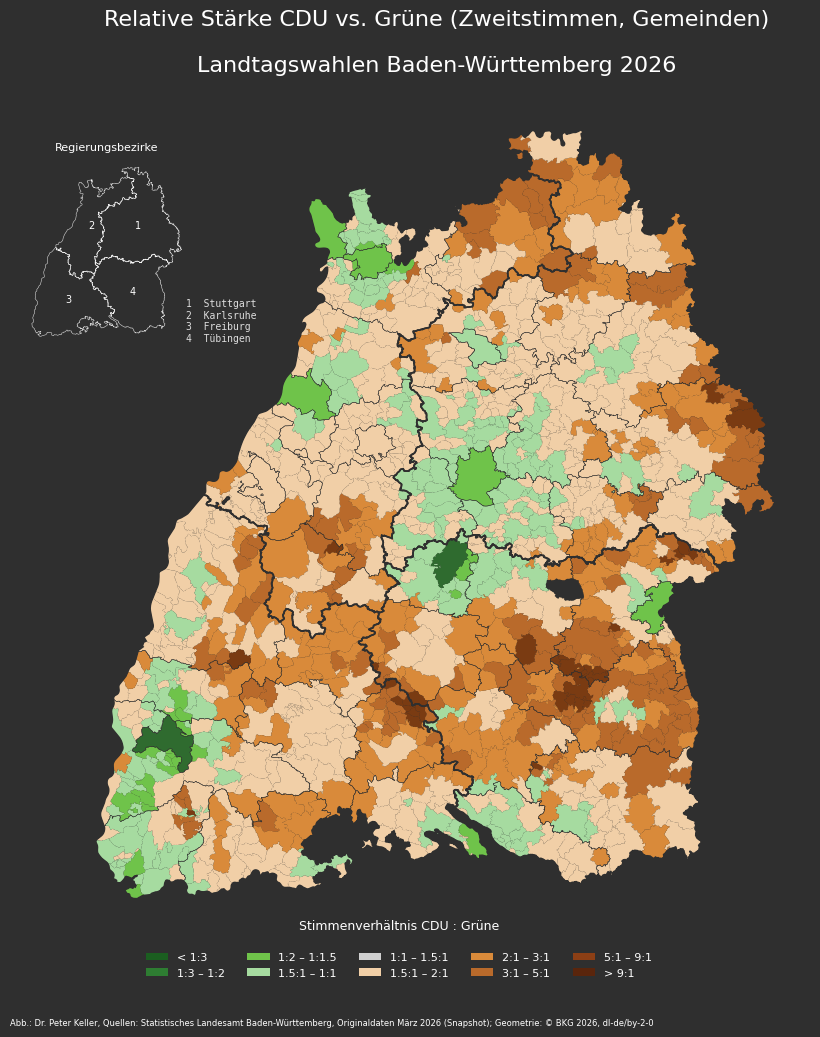

saved outputs/ZST_Wahlergebnis_LTW_BW_2026_logratio_kat.png


In [11]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np

# =========================
# EINSTELLUNGEN
# =========================
vote_type = "ZST"   # "EST" oder "ZST"

label1 = "CDU"
label2 = "Grüne"

# =========================
# INDEX
# =========================
# R_log = natürlicher Logarithmus des CDU/Grüne-Verhältnisses

# Asymmetrische Klassen mit betontem Neutralbereich um 1:1
# log(1.5) ≈ 0.405  -> enger Gleichgewichtsbereich
# log(2)   ≈ 0.693
# log(3)   ≈ 1.099
# log(5)   ≈ 1.609
rmin = gdf["R_log"].min() - 1e-6
rmax = gdf["R_log"].max() + 1e-6

# neue Klassen mit Split bei 1:1
bins = np.array([
    rmin,
    -np.log(3),
    -np.log(1.5),
    0,
    np.log(1.5),
    np.log(2),
    np.log(3),
    rmax
])

# Farben: leicht grün links von 1:1, leicht orange rechts
colors = [
    "#2f6b2f",  # starke Grünen-Dominanz
    "#6fc34a",  # moderate Grünen-Dominanz
    "#a6dba0",  # leicht grün (nahe 1:1)
    "#f1cfa7",  # leicht orange (nahe 1:1)
    "#d98a3a",  # moderate CDU-Dominanz
    "#b96a2b",  # starke CDU-Dominanz
    "#7a3b12"   # sehr starke CDU-Dominanz
]

# Labels
tick_labels = [
    "< 1:3",
    "1:3 bis 1:1.5",
    "1:1.5 bis 1:1",
    "1:1 bis 1.5:1",
    "1.5:1 bis 2:1",
    "2:1 bis 3:1",
    "> 3:1"
]

cmap = ListedColormap(colors)
norm = BoundaryNorm(bins, cmap.N)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

# =========================
# LAYOUT
# =========================
fig = plt.figure(figsize=(11, 12))
fig.patch.set_facecolor("#2f2f2f")

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[18, 0.9],
    hspace=0.08
)

ax = fig.add_subplot(gs[0, 0])
# cax = fig.add_subplot(gs[1, 0])

ax.set_facecolor("#2f2f2f")
# cax.set_facecolor("#2f2f2f")

# =========================
# KARTE
# =========================
gdf.plot(
    column="R_log",
    ax=ax,
    cmap=cmap,
    norm=norm,
    linewidth=0,
    zorder=5
)

# p2 = BWB.boundary.plot(ax=ax, edgecolor="white", zorder=0)
# p2.set_path_effects([
#     pe.Stroke(linewidth=1.5, foreground="white"),
#     pe.Normal()
# ])

BWB_kreise.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=0.3, zorder=10)
BWB_regbez.boundary.plot(ax=ax, edgecolor="#2f2f2f", linewidth=1.2, zorder=11)

ax.set_title(
    f"Relative Stärke {label1} vs. {label2} (Zweitstimmen, Gemeinden)\n\nLandtagswahlen Baden-Württemberg 2026",
    color="white",
    fontsize=16,
    pad=14
)
ax.set_axis_off()

# =========================
# Legende
# =========================
from matplotlib.patches import Patch

# example color ramp (green → grey → orange/brown)
colors = [
    "#1b5e20",
    "#2e7d32",
    "#6fc34a",
    "#a6dba0",
    "#d0d0d0",
    "#f1cfa7",
    "#d98a3a",
    "#b96a2b",
    "#8c3f15",
    "#5a250c"
]

legend_labels = [
    "< 1:3",
    "1:3 – 1:2",
    "1:2 – 1:1.5",
    "1.5:1 – 1:1",
    "1:1 – 1.5:1",
    "1.5:1 – 2:1",
    "2:1 – 3:1",
    "3:1 – 5:1",
    "5:1 – 9:1",
    "> 9:1"
]

handles = [
    Patch(facecolor=c, edgecolor="none", label=l)
    for c, l in zip(colors, legend_labels)
]

leg = ax.legend(
    handles=handles,
    title="Stimmenverhältnis CDU : Grüne\n",
    loc="lower center",
    bbox_to_anchor=(0.45, -0.06),
    ncol = 5,
    fontsize = 8,
    title_fontsize = 9,
    frameon = False,
)

plt.setp(leg.get_texts(), color="white")
leg.get_title().set_color("white")

# cax.set_axis_off()

# =========================
# INSET REGIERUNGSBEZIRKE
# =========================
regbez_map = ax.inset_axes([-0.05, 0.7, 0.22, 0.22])

BWB_regbez.boundary.plot(
    ax=regbez_map,
    edgecolor="white",
    facecolor="none",
    linewidth=0.4,
    alpha=0.8,
)

regbez_map.set_xticks([])
regbez_map.set_yticks([])
regbez_map.set_title("Regierungsbezirke", fontsize=8, color="white")
regbez_map.set_facecolor("none")
regbez_map.set_frame_on(False)

xs = BWB_regbez.centers.geometry.x
ys = BWB_regbez.centers.geometry.y
nrs = BWB_regbez.RegBez_Nr

for x, y, nr in zip(xs, ys, nrs):
    regbez_map.text(
        x, y, nr,
        ha="center", va="center",
        color="white", fontsize=7
    )

liste = "\n".join(
    f"{row['RegBez_Nr']}  {row['RegBez_Name']}"
    for _, row in BWB_regbez[['RegBez_Nr', 'RegBez_Name']].iterrows()
)

regbez_map.text(
    0.98, 0.25,
    liste,
    transform=regbez_map.transAxes,
    fontsize=7,
    color="#dddddd",
    va="top",
    family="monospace"
)

# =========================
# FOOTER
# =========================
fig.text(
    0.125, 0.1,
    "Abb.: Dr. Peter Keller, Quellen: Statistisches Landesamt Baden-Württemberg, Originaldaten März 2026 (Snapshot); Geometrie: © BKG 2026, dl-de/by-2-0",
    fontsize=6,
    ha="left",
    va="bottom",
    color="white"
)

plt.show()
filename = f'outputs/{vote_type}_Wahlergebnis_LTW_BW_2026_logratio_kat.png'
dpi = 300

fig.savefig(
    filename, 
    dpi=dpi,
    bbox_inches="tight",
    transparent = False,
)
print(f'saved {filename}')
plt.close(fig)

## 7. Ternär: CDU, Grüne und alle übrigen Parteien

Anders als das reine Verhältnis behält das Dreieck den gemeinsamen Anteil der beiden Parteien im Blick. Die drei Komponenten summieren sich zu 100 %. „Rest“ fasst heterogene Parteien zusammen; eine ähnliche Lage bedeutet deshalb keine ähnliche politische Zusammensetzung innerhalb des Restes.

Jeder Punkt steht für eine Gemeinde. Alle Punkte haben dieselbe Größe und Farbe; es erfolgt keine Gewichtung nach der Zahl gültiger Stimmen. Die markierten Eckbereiche bedeuten mehr als 50 % für eine Komponente, nicht bloß die relativ stärkste Komponente.

Der Diamant zeigt die auf Summe 1 normierten komponentenweisen Mediane. Er ist kein multivariater Median und kein nach Stimmen gewichtetes Landesergebnis.


In [12]:
ternary = df[['AGS','gemeindename','GRUENE_ZST', 'CDU_ZST']].copy().reset_index()
ternary['GES'] = df['zweitstimmen_gueltig']

ternary['gemeindename'] = ternary['gemeindename'].str.split(',').str[0]

parties = ['GRUENE', 'CDU']

for party in parties:
    ternary[f'{party}_shr'] = ternary[f'{party}_ZST'] / ternary['GES']

ternary['rest_shr'] = 1 - ternary['GRUENE_shr'] - ternary['CDU_shr']

ternary['REGBEZ'] = df['AGS'].str[:3]
ternary['REGBEZ_name'] = ternary['REGBEZ'].map(regbez_dict)

colors = {
    'Stuttgart' : '#1b9e77',
    'Karlsruhe' : '#d95f02',
    'Freiburg'  : '#7570b3',
    'Tübingen'  : '#e7298a',
}

ternary['RegBez_cm'] = ternary['REGBEZ_name'].map(colors)

ternary
display(ternary.head())

,index,AGS,gemeindename,GRUENE_ZST,CDU_ZST,GES,GRUENE_shr,CDU_shr,rest_shr,REGBEZ,REGBEZ_name,RegBez_cm
0,0,08111000,Stuttgart,106237,63233,259544,0.409322,0.243631,0.347047,081,Stuttgart,#1b9e77
1,1,08115001,Aidlingen,1494,1664,4926,0.303289,0.337799,0.358912,081,Stuttgart,#1b9e77
2,2,08115002,Altdorf,921,916,2689,0.342507,0.340647,0.316846,081,Stuttgart,#1b9e77
3,3,08115003,Böblingen,6370,5513,19314,0.329813,0.285441,0.384747,081,Stuttgart,#1b9e77
4,4,08115004,Bondorf,1015,1039,3264,0.310968,0.318321,0.370711,081,Stuttgart,#1b9e77


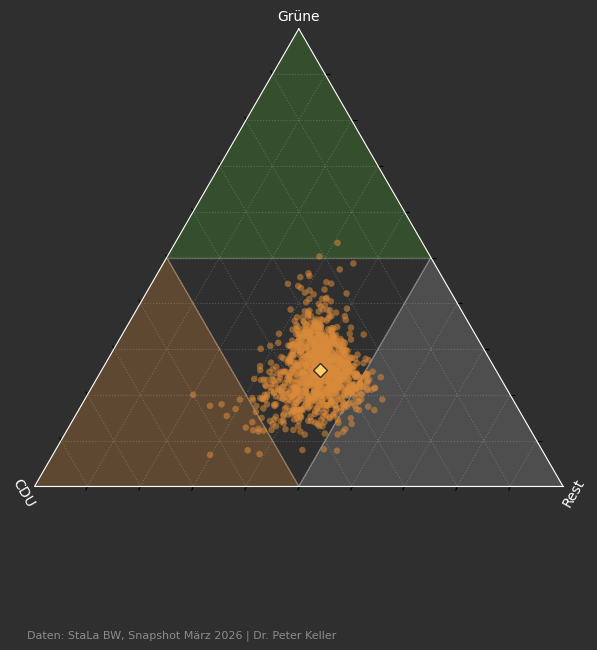

saved outputs/CDU_GRUENE_REST_ternary.png


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import mpltern

# importing the tools for ternary and ILR
import election_tools as tirl

# ----------------------------
# Palette
# ----------------------------
pc = {
    "GRUENE": "#46962b",
    "CDU": "#d98a3a",
    "rest": "#bfbfbf",   # neutral statt blau
}

# ----------------------------
# Figure / axis
# ----------------------------
fig = plt.figure(figsize=(15, 15))
fig.patch.set_facecolor("#2f2f2f")

ax = fig.add_subplot(
    1, 2, 1,
    projection="ternary",
)

ax.patch.set_facecolor("none")

# ----------------------------
# Axis setup
# ----------------------------
tirl.setup_ternary_axis(
    ax,
    major_step=10,
    draw_grid=True,
    draw_subgrid=True,
    show_labels=False,
)

ax.set_tlabel("Grüne", color="white")
ax.set_llabel("CDU", color="white")
ax.set_rlabel("Rest", color="white")

# Tick/Grid-Farben etwas weicher
ax.grid(color="white", alpha=0.18)
for spine in ax.spines.values():
    spine.set_color("white")

# ----------------------------
# Dominanzbereiche
# ----------------------------
ax.fill(
    [1.0, 0.5, 0.5], [0.0, 0.5, 0.0], [0.0, 0.0, 0.5],
    color=pc["GRUENE"],
    alpha=0.30,
    zorder=1,
)

ax.fill(
    [0.0, 0.5, 0.0], [1.0, 0.5, 0.5], [0.0, 0.0, 0.5],
    color=pc["CDU"],
    alpha=0.28,
    zorder=1,
)

ax.fill(
    [0.0, 0.5, 0.0], [0.0, 0.0, 0.5], [1.0, 0.5, 0.5],
    color=pc["rest"],
    alpha=0.22,
    zorder=1,
)

# 50%-Grenzen optional leicht betonen
ax.plot([0.5, 0.5], [0.5, 0.0], [0.0, 0.5], color="white", alpha=0.20, lw=1)
ax.plot([0.5, 0.0], [0.0, 0.5], [0.5, 0.5], color="white", alpha=0.20, lw=1)
ax.plot([0.0, 0.5], [0.5, 0.5], [0.5, 0.0], color="white", alpha=0.20, lw=1)

# ----------------------------
# Scatter
# ----------------------------
# Jede Gemeinde erhält dasselbe visuelle Gewicht.
sc = ax.scatter(
    ternary["GRUENE_shr"],
    ternary["CDU_shr"],
    ternary["rest_shr"],
    s=22,
    color="#d98a3a",
    alpha=0.55,
    edgecolors="none",
    zorder=5,
    clip_on=False,
)

# ----------------------------
# Median-Punkt + Annotation
# ----------------------------
median_share = ternary[["GRUENE_shr", "CDU_shr", "rest_shr"]].median()
median_share = median_share / median_share.sum()

t_med = median_share["GRUENE_shr"]
l_med = median_share["CDU_shr"]
r_med = median_share["rest_shr"]

ax.plot(
    t_med, l_med, r_med,
    marker="D",
    markersize=7,
    markerfacecolor="#ffcc66",
    markeredgecolor="#2f2f2f",
    zorder=50,
)

# ----------------------------
# Footer
# ----------------------------
foot = "Daten: StaLa BW, Snapshot März 2026 | Dr. Peter Keller"
fig.text(
    0.12, 0.24,
    foot,
    ha="left",
    va="bottom",
    fontsize=8,
    color="0.55"
)

plt.show()
filename = f'outputs/CDU_GRUENE_REST_ternary.png'
dpi = 120

fig.savefig(
    filename, 
    dpi=dpi,
    bbox_inches="tight",
    transparent = False,
)
print(f'saved {filename}')
plt.close(fig)

## 8. Stärkste Partei je Gemeinde

Die Gewinnerkarte reduziert die Parteianteile auf einen Namen. Das erleichtert die Orientierung, verbirgt aber knappe Abstände und die Stimmen der übrigen Parteien. Eine große Fläche in der Karte steht nicht für viele Wählende. Gleichstände werden gesondert behandelt.

Die Parteifarben zeigen ausschließlich die jeweils stärkste Partei nach Zweitstimmen. Zum Vergleich bleiben die Anteils- und Verhältniskarten in den vorherigen Abschnitten erhalten.


In [14]:
party_colors = {
    "GRUENE"   : "#46962b",
    "CDU"      : "#000000", # '#d98a3a',
    "SPD"      : "#e3000f",
    "FDP"      : "#ffed00",
    "AfD"      : "#009ee0",
    "Die_Linke": "#be3075",
}

party_colors["Gleichstand"] = "#bfbfbf"
gdf['winner_ZST_col'] = gdf['winner_ZST'].map(party_colors)

saved outputs/Staerkste_Partei_Gemeinden.png


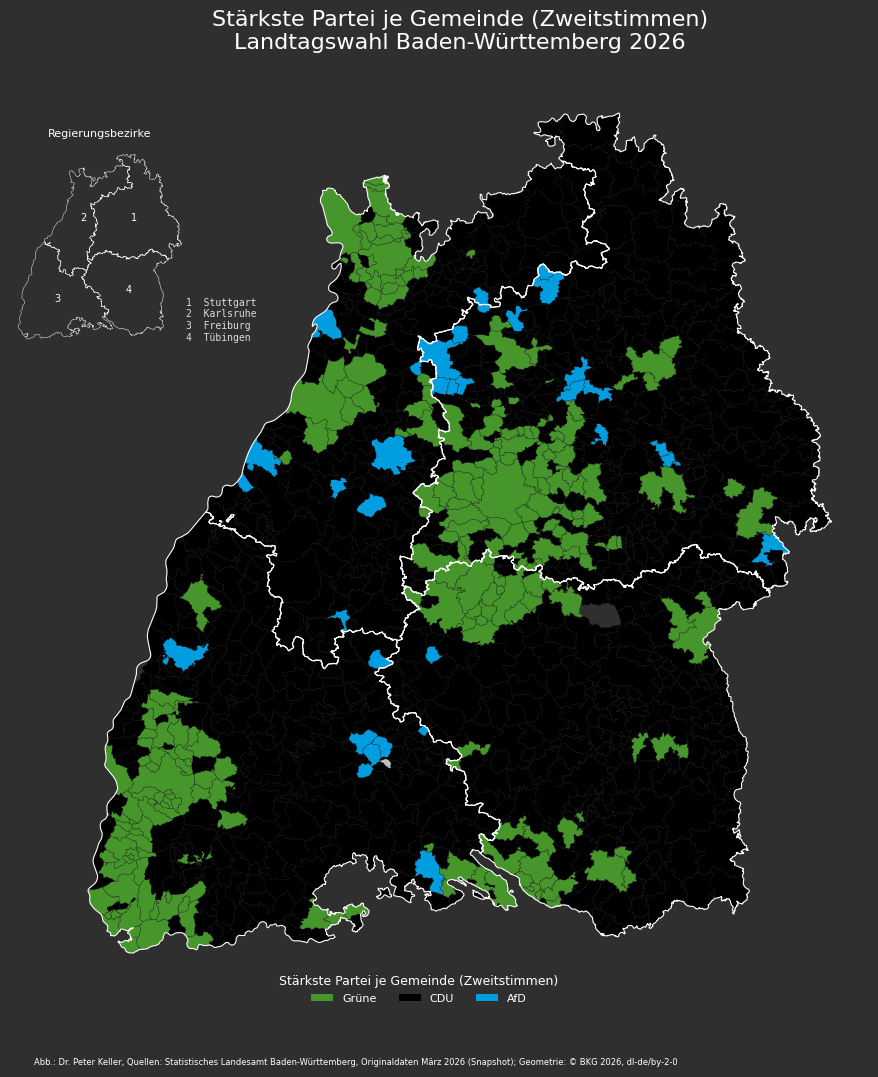

In [15]:
fig, ax = plt.subplots(1,1,figsize=(11, 12))

fig.patch.set_facecolor("#2f2f2f")
ax.set_facecolor("#2f2f2f")

# =========================
# MAP
# =========================
gdf.plot(
    color=gdf['winner_ZST_col'],
    ax=ax,
    edgecolor = '#202020',
    linewidth = 0.2,
)

BWB_regbez.boundary.plot(
    edgecolor='white',
    facecolor='none',
    linewidth=0.8,
    ax=ax,
)

# =========================
# TITLE
# =========================
ax.set_title(
    "Stärkste Partei je Gemeinde (Zweitstimmen)\n"
    "Landtagswahl Baden-Württemberg 2026",
    color="white",
    fontsize=16,
    pad=16
)

# =========================
# INSET REGIERUNGSBEZIRKE
# =========================
regbez_map = ax.inset_axes([-0.05, 0.7, 0.22, 0.22])

BWB_regbez.boundary.plot(
    ax=regbez_map,
    edgecolor="white",
    facecolor="none",
    linewidth=0.4,
    alpha=0.8,
)

regbez_map.set_xticks([])
regbez_map.set_yticks([])
regbez_map.set_title("Regierungsbezirke", fontsize=8, color="white")
regbez_map.set_facecolor("none")
regbez_map.set_frame_on(False)

xs = BWB_regbez.centers.geometry.x
ys = BWB_regbez.centers.geometry.y
nrs = BWB_regbez.RegBez_Nr

for x, y, nr in zip(xs, ys, nrs):
    regbez_map.text(
        x, y, nr,
        ha="center", va="center",
        color="white", fontsize=7
    )

liste = "\n".join(
    f"{row['RegBez_Nr']}  {row['RegBez_Name']}"
    for _, row in BWB_regbez[['RegBez_Nr','RegBez_Name']].iterrows()
)

regbez_map.text(
    0.98, 0.25,
    liste,
    transform=regbez_map.transAxes,
    fontsize=7,
    color="#dddddd",
    va="top",
    family="monospace"
)

# =========================
# Legende
# =========================
from matplotlib.patches import Patch

legend_labels = [
    "Grüne",
    "CDU",
    "AfD",
]

colors = [
    "#46962b",
    "#000000", # '#d98a3a',
    "#009ee0",
]

handles = [
    Patch(facecolor=c, edgecolor="none", label=l)
    for c, l in zip(colors, legend_labels)
]

leg = ax.legend(
    handles=handles,
    title="Stärkste Partei je Gemeinde (Zweitstimmen)",
    loc="lower center",
    bbox_to_anchor=(0.45, -0.02),
    ncol = 3,
    fontsize = 8,
    title_fontsize = 9,
    frameon = False,
)

plt.setp(leg.get_texts(), color="white")
leg.get_title().set_color("white")

# =========================
# FOOTER
# =========================
fig.text(
    0.125, 0.05,
    "Abb.: Dr. Peter Keller, Quellen: Statistisches Landesamt Baden-Württemberg, Originaldaten März 2026 (Snapshot); Geometrie: © BKG 2026, dl-de/by-2-0",
    fontsize=6,
    ha="left",
    va="bottom",
    color="white"
)

ax.set_axis_off()
filename = f'outputs/Staerkste_Partei_Gemeinden.png'
dpi = 120

fig.savefig(
    filename, 
    dpi=dpi,
    bbox_inches="tight",
    transparent = False,
)
print(f'saved {filename}')
plt.show()
plt.close(fig)

## 9. Räumliche Autokorrelation: R und log(R) im Vergleich

Im ursprünglichen Notebook wurden Moran und LISA auf R = CDU/Grüne berechnet, die LISA-Karte jedoch als log(R) beschriftet. Beide Varianten bleiben hier als expliziter Vergleich erhalten. R betont große Verhältnisse stärker; die logarithmierte Variante verändert deshalb auch die Nachbarschaftsstatistik.

Queen-Nachbarschaft zählt gemeinsame Kanten oder Punkte. Die Gewichte werden zeilenstandardisiert. Inseln werden ausgewiesen und aus der statistischen Auswertung ausgeschlossen; es werden keine künstlichen Nachbarn ergänzt. Zufallsstart und Permutationszahl sind festgelegt.

LISA wird sowohl mit der ursprünglichen lokalen Schwelle p < 0,05 als auch mit Benjamini-Hochberg-Korrektur gezeigt. Die erste Ansicht ist explorativ und kontrolliert keine gemeinsame Fehlerrate. BH ist eine zusätzliche Sensitivitätsansicht; räumliche Abhängigkeit macht die Interpretation der p-Werte nicht voraussetzungslos. HH/LL beziehen sich auf hohe/niedrige Werte relativ zum Mittel, nicht auf eine absolute Mehrheit einer Partei.


site-packages/libpysal\weights\contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 757.
  W.__init__(self, neighbors, ids=ids, **kw)


Inseln ohne Queen-Nachbarn: ['08335015']


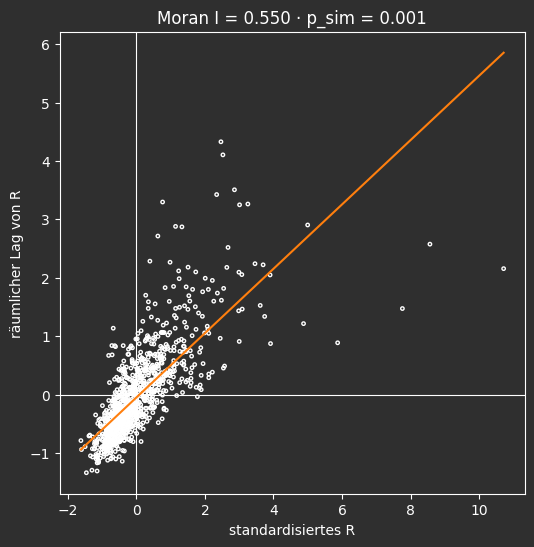

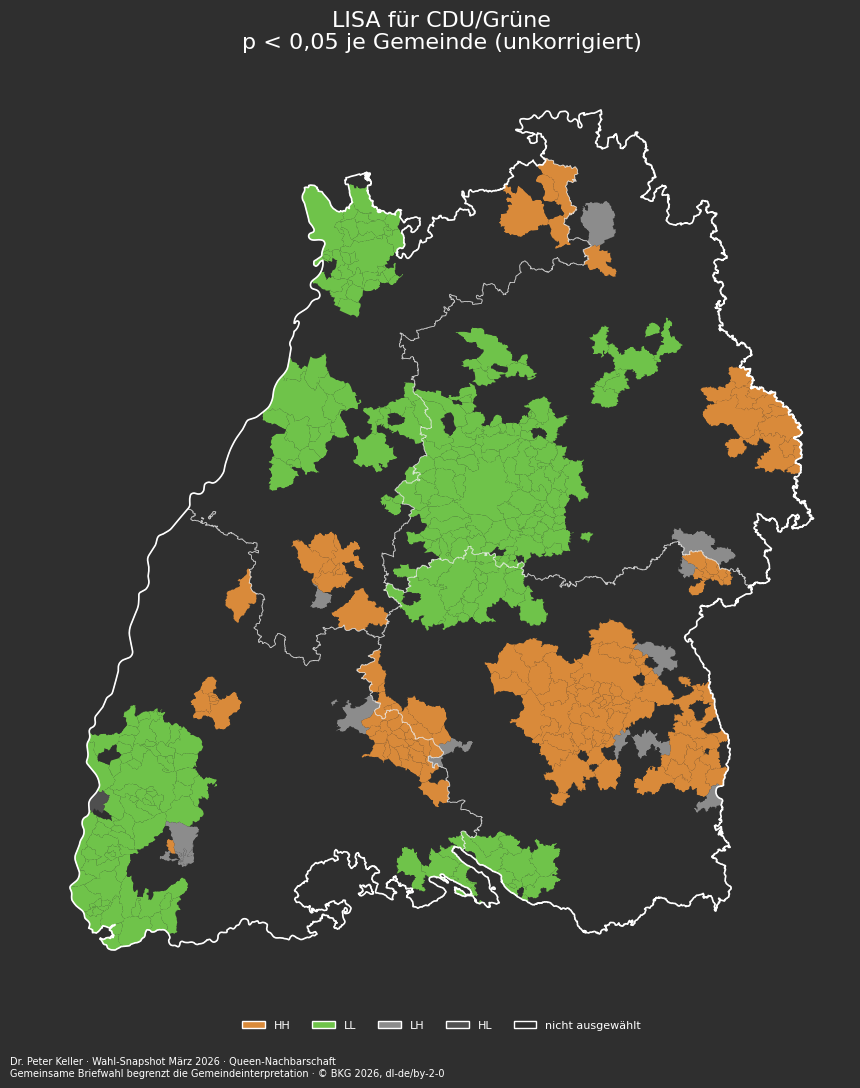

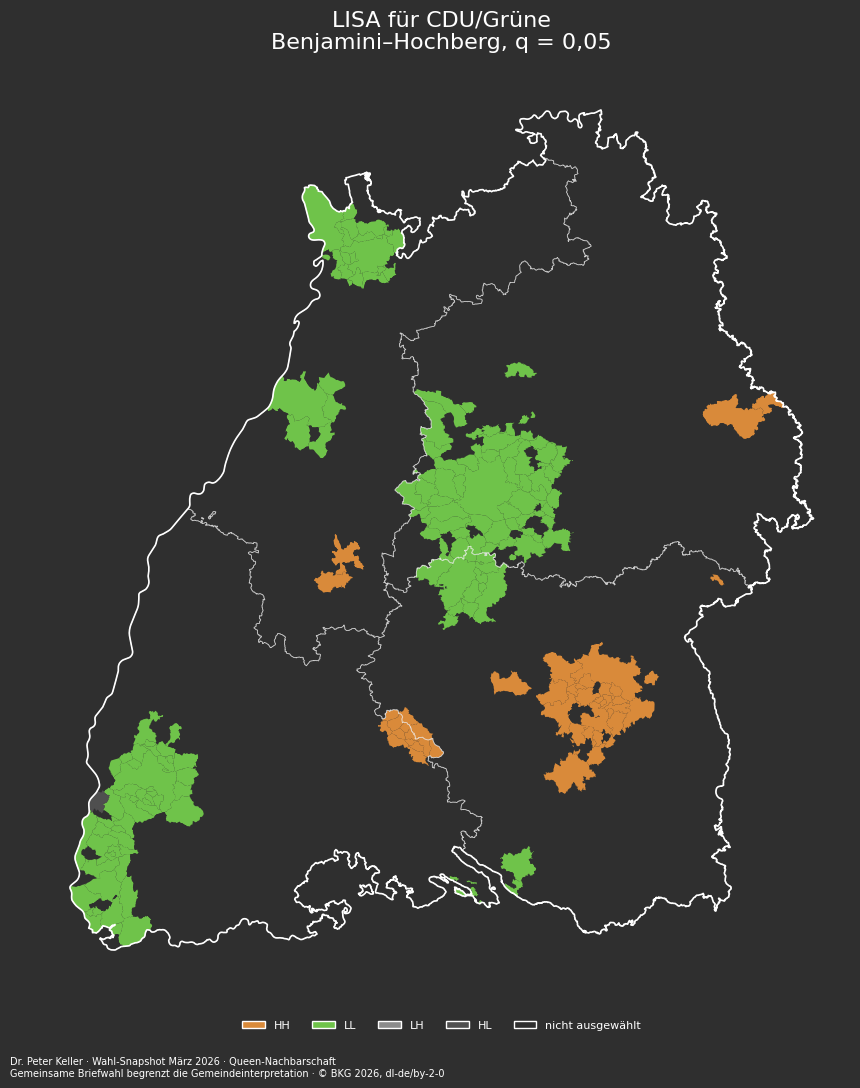

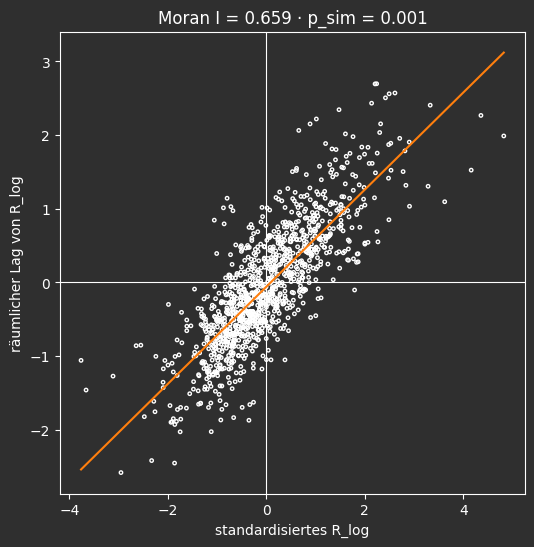

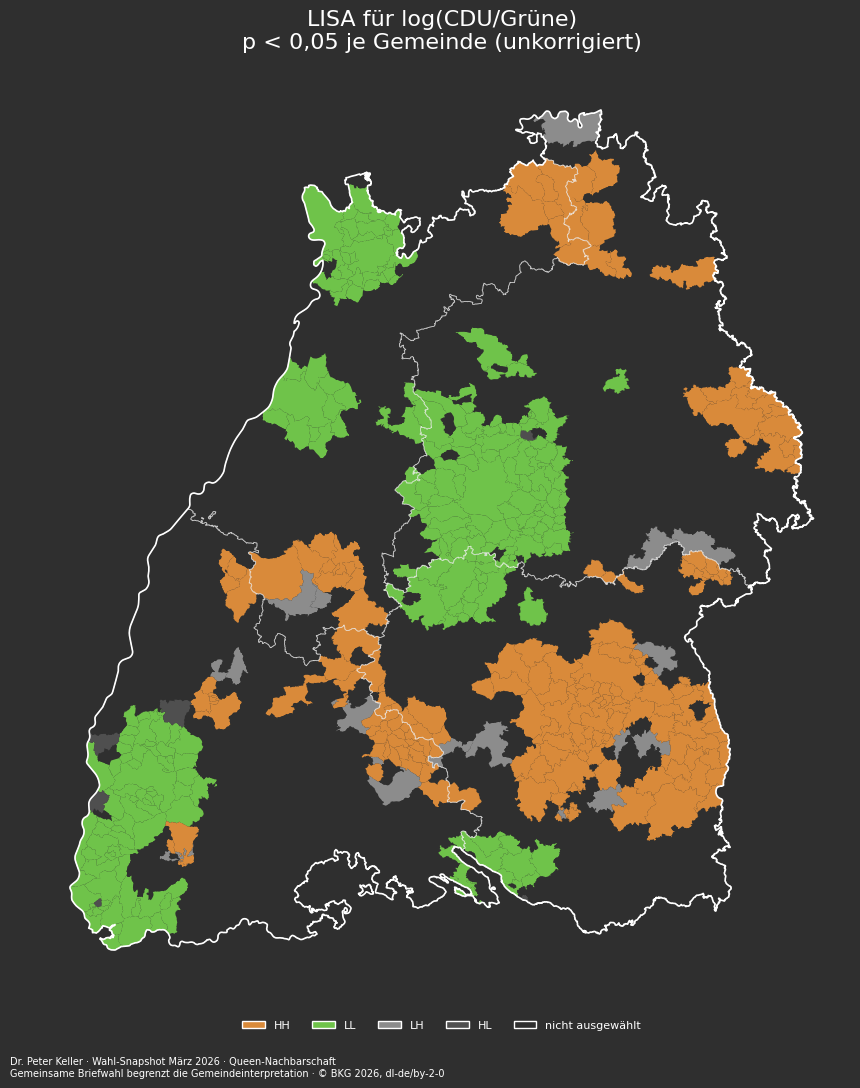

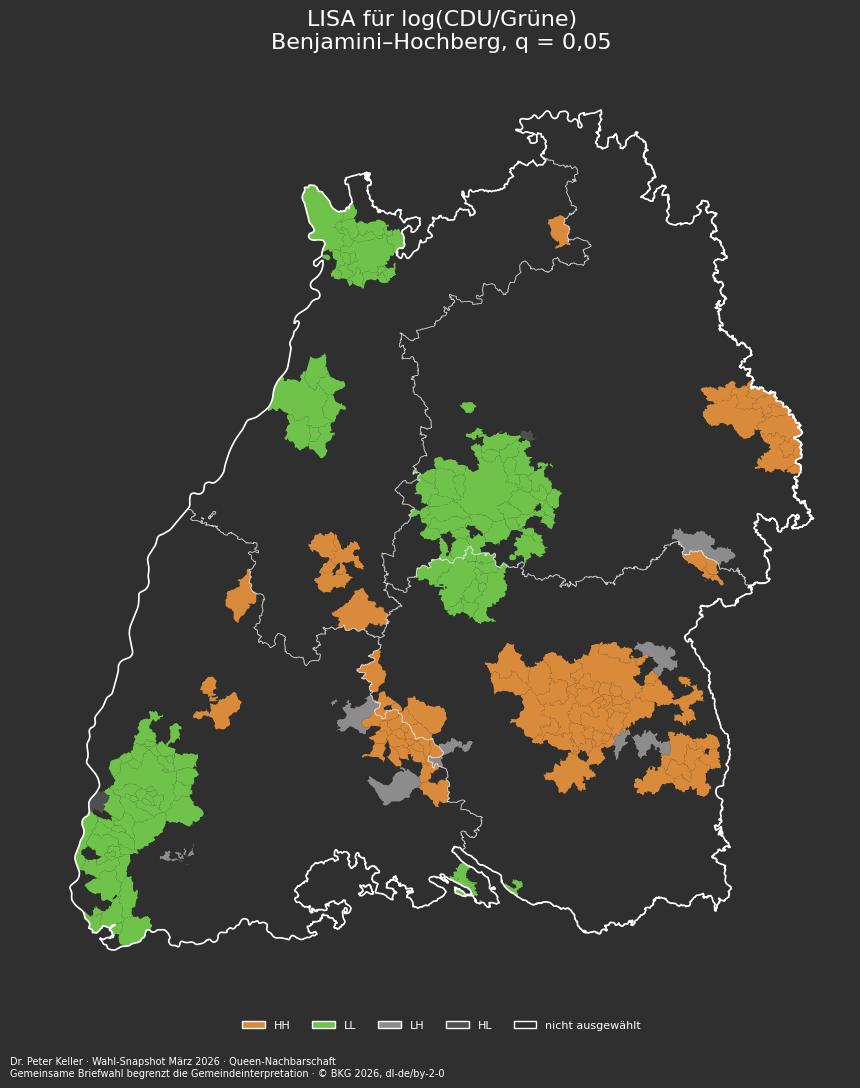

,Variable,Gemeinden,Moran_I,p_sim,LISA_lokal_ausgewählt,LISA_BH_ausgewählt
0,R,1100,0.550446,0.001,396,186
1,R_log,1100,0.658841,0.001,418,227


In [16]:
from libpysal.weights import Queen, lag_spatial
from esda.moran import Moran, Moran_Local
from matplotlib.patches import Patch

gdf_m = gdf[['AGS', 'R', 'R_log', 'geometry']].replace([np.inf, -np.inf], np.nan).dropna().copy()
gdf_m = gdf_m.sort_values('AGS').reset_index(drop=True)
w = Queen.from_dataframe(gdf_m, use_index=False)
print('Inseln ohne Queen-Nachbarn:', gdf_m.iloc[w.islands].AGS.tolist())
while w.islands:
    gdf_m = gdf_m.drop(index=w.islands).reset_index(drop=True)
    w = Queen.from_dataframe(gdf_m, use_index=False)
w.transform = 'r'

palette = {'HH': '#d98a3a', 'LL': '#6fc34a', 'LH': '#8c8c8c',
           'HL': '#4f4f4f', 'nicht ausgewählt': '#2f2f2f'}
statistics = []
for variable in ('R', 'R_log'):
    np.random.seed(SEED)
    mi = Moran(gdf_m[variable].to_numpy(), w, permutations=PERMUTATIONS)
    lisa = Moran_Local(gdf_m[variable].to_numpy(), w, permutations=PERMUTATIONS,
                       seed=SEED, n_jobs=1, keep_simulations=False)
    statistics.append({'Variable': variable, 'Gemeinden': len(gdf_m),
                       'Moran_I': mi.I, 'p_sim': mi.p_sim})
    z = (gdf_m[variable] - gdf_m[variable].mean()) / gdf_m[variable].std(ddof=0)
    wz = lag_spatial(w, z)
    fig, ax = plt.subplots(figsize=(6, 6), facecolor='#2f2f2f')
    ax.set_facecolor('#2f2f2f')
    ax.scatter(z, wz, s=6, edgecolor='white', facecolor='none')
    ax.axhline(0, color='white', lw=.8)
    ax.axvline(0, color='white', lw=.8)
    b, a = np.polyfit(z, wz, 1)
    xx = np.linspace(z.min(), z.max(), 200)
    ax.plot(xx, a + b * xx, color='tab:orange')
    ax.set(xlabel=f'standardisiertes {variable}', ylabel=f'räumlicher Lag von {variable}')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_color('white')
    ax.set_title(f'Moran I = {mi.I:.3f} · p_sim = {mi.p_sim:.3f}', color='white')
    fig.savefig(OUTPUT / f'moran_{variable}.png', dpi=120, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    labels = np.array(['', 'HH', 'LH', 'LL', 'HL'])[lisa.q]
    for name, selected in [('lokal', lisa.p_sim < .05), ('BH', fdr_bh(lisa.p_sim))]:
        categories = np.where(selected, labels, 'nicht ausgewählt')
        fig, ax = plt.subplots(figsize=(11, 12), facecolor='#2f2f2f')
        ax.set_facecolor('#2f2f2f')
        gdf_m.plot(color=pd.Series(categories).map(palette).to_numpy(), ax=ax, linewidth=0)
        BWB.boundary.plot(ax=ax, edgecolor='white', linewidth=1.2)
        BWB_regbez.boundary.plot(ax=ax, edgecolor='white', linewidth=.6, alpha=.5)
        title = 'p < 0,05 je Gemeinde (unkorrigiert)' if name == 'lokal' else 'Benjamini–Hochberg, q = 0,05'
        variable_label = 'CDU/Grüne' if variable == 'R' else 'log(CDU/Grüne)'
        ax.set_title(f'LISA für {variable_label}\n{title}', color='white', fontsize=16, pad=14)
        handles = [Patch(facecolor=color, edgecolor='white', label=label) for label, color in palette.items()]
        legend = ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, -.02),
                           ncol=5, frameon=False, fontsize=8)
        plt.setp(legend.get_texts(), color='white')
        ax.set_axis_off()
        fig.text(.12, .04, 'Dr. Peter Keller · Wahl-Snapshot März 2026 · Queen-Nachbarschaft\n'
                 'Gemeinsame Briefwahl begrenzt die Gemeindeinterpretation · © BKG 2026, dl-de/by-2-0', color='white', fontsize=7)
        fig.savefig(OUTPUT / f'lisa_{variable}_{name}.png', dpi=120, bbox_inches='tight')
        plt.show()
        plt.close(fig)
        statistics[-1][f'LISA_{name}_ausgewählt'] = int(selected.sum())
display(pd.DataFrame(statistics))
pd.DataFrame(statistics).to_csv(OUTPUT / 'raumstatistik.csv', index=False)


## Was bleibt offen?

Die Varianten ergeben unterschiedliche Lesarten desselben Datenstands. Eine einzelne „beste“ Karte wird hier bewusst nicht behauptet. Die nächste fachliche Erweiterung wäre ein getrennt dokumentierter Vergleich mit dem endgültigen Wahlstand und eine Untersuchung der Sensitivität gegenüber der Nachbarschaftsdefinition.
